# Process 이상탐지 결과 — 전후 행 수 · 분포 · 판정선 · 탐지 근거

이 노트북은 **“몇 행이 걸렸고, 어떤 값이 어떤 기준을 넘어서 걸렸는가?”**를 읽는 보고서다. 세 기간의 Process를 합쳐, 이미 저장한 모델로 다시 추론한다. 모델을 재학습하거나 기준을 바꾸지 않는다.

| 먼저 볼 부분 | 답하는 질문 |
|---|---|
| 1. 규칙 전후 데이터 개수 | 원본 → 규칙 후보 분리 → IF 평가 가능 → IF 추가 후보 분리. 각 단계에서 몇 행이 남는가? |
| 2. 전체 입력 분포와 통계 기준 | 처리시간·처리건수·재시도가 어떻게 분포하고, 실제 P99/P99.9 기준은 얼마인가? |
| 3. IF 분포와 판정선 | 어떤 점수를 사용하며, 어디를 넘으면 IF 후보인가? |
| 4. 최종 결과 | 규칙만·IF만·중복·미탐지·미평가가 각각 몇 행인가? |
| 5. 실제 탐지 사례 | 실측값과 기준값을 비교했을 때, 이 행은 정확히 왜 후보가 됐는가? |
| 6. 결론 / 부록 | 결과 해석과 한계, 학습 설정·Adapter 지원·기간별 상세 |

**단위는 Process 실행 1행이다.** 한 Transaction의 여러 Process가 잡히면 여러 행이다. “후보”는 검토 대상이지 확인된 장애 정답이 아니고, **미평가는 정상 판정이 아니다.** 표는 전수 집계이며 표본 그림은 표본 수를 명시한다. 분석 결과 CSV 저장 셀은 없다.


> 이번 공유 범위: 최종 v12 IF/K-means, 전체 연구 코드·노트북, 원본 inputs.json·학습/검증 캐시. 기간별 원본과 벤치마크 CSV·정답·행별 NPZ는 보류했습니다. 이전 실험의 모델 바이너리는 제외했으며 저장된 결과와 실제 재실행 가능 범위는 다릅니다. 최신 결과는 model_research_v8/results.ipynb와 benchmark_difficulty/comparison.ipynb, 로드 안내는 패키지 README.md·INTEGRATION.md를 참고하세요.

### 실행 준비

**실행 결과가 이미 저장돼 있으므로 우선 1절부터 읽으면 된다.** 다시 실행할 때만 `.analysis-venv`의 Python 커널을 선택하고 위에서 아래로 실행한다. 원본 370만여 행과 Transaction 관계를 전수로 읽으므로 메모리와 시간이 필요하다. 아래 코드에서 저장 모델을 1회 로드하며 `fit()`은 호출하지 않는다.


In [1]:
from pathlib import Path
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CODE = next(q for root in [Path.cwd(), *Path.cwd().parents] for q in (root, root / "code")
            if (q / "process_anomaly_pipeline").is_dir())
sys.path.insert(0, str(CODE))

from process_anomaly_pipeline import ProcessAnomalyPipeline
from process_anomaly_pipeline.data import load_workspace
from process_anomaly_pipeline.analysis import (
    set_style, experiment_split, reference_mask, rule_audit, relation_summary,
    outcome_summary, adapter_model_support, plot_training_mix, plot_model_scores,
    plot_status, plot_daily, plot_population, plot_input_features,
    plot_duration_distributions, plot_test_score_timeline,
)
from process_anomaly_pipeline.report import (
    RULE_LABELS, detection_counts, flow_table, partition_table, rule_removal_table,
    group_filter_counts, training_filter_table, adapter_training_counts,
    full_numeric_summary, statistical_threshold_table, route_threshold_table,
    plot_flow, plot_rule_removals, plot_partitions, plot_full_inputs,
    plot_full_score_margins, select_case_indices, case_evidence_table, case_feature_table, case_context_text,
)

MODEL = CODE / "process_anomaly_pipeline/artifacts/process_if_v1.joblib"
pipeline = ProcessAnomalyPipeline.load(MODEL, trusted=True)
set_style()
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}".rstrip("0").rstrip("."))
print(f"저장 모델: {MODEL.name} / Python {platform.python_version()}")


저장 모델: process_if_v1.joblib / Python 3.12.14


### 원본 출처 확인

파일명만 보지 않고 실제 컬럼을 확인해 Process/Transaction을 읽는다. 아래 출처 표에서 세 기간을 확인한다. 같은 기간의 Transaction은 두 관계 규칙의 참고 정보로만 쓰며, IF 입력 피처와 판정 단위는 Process다.

저장 모델과 **출처·행 수가 같은 실험**인지 확인한다. 이 확인은 파일 내용의 해시 검증은 아니다.


In [2]:
p, t, sources = load_workspace(CODE.parent / "data", with_transactions=True)
display(pd.DataFrame(sources))
print(f"Process {len(p):,}행 / Transaction {len(t):,}행 / Adapter {p.adapterType.nunique():,}종")

def source_signature(rows):
    return sorted((x["kind"], x["period"], Path(x["source"]).name, x["rows"], x["format"])
                  for x in rows)

assert len(p) == pipeline.training_summary["rows"]
assert source_signature(sources.to_dict("records")) == source_signature(pipeline.training_summary["sources"])


,kind,period,source,rows,format
0,process,25년12월24일-26년4월6일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\25년12월2...,3473285,csv
1,process,26년8월15일-26년9월14일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년8월15...,213509,csv
2,process,26년9월30일-26년10월2일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년9월30...,27405,csv
3,transaction,25년12월24일-26년4월6일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\25년12월2...,1768054,csv
4,transaction,26년8월15일-26년9월14일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년8월15...,213381,csv
5,transaction,26년9월30일-26년10월2일,C:\Users\drago\OneDrive\바탕 화면\종설2\data\26년9월30...,27268,sql


Process 3,714,199행 / Transaction 2,008,703행 / Adapter 24종


### 전수 추론 — 관계 규칙의 전제

세 기간 전체 export를 제공한 조건으로 `complete_context=True`를 사용한다. 이것은 **“해당 거래의 전체 Process가 수집됐다”는 분석 전제**이지, 수집 완전성을 증명한 결과가 아니다. 관계 오류를 확정하려면 운영 담당자의 확인이 필요하다.

현재 추론 코드는 규칙 후보도 삭제하지 않고 결과에 남긴다. 유효한 규칙 후보에는 IF도 계산한다. 뒤의 “전후 행 수”는 **후보를 별도 집단으로 분리해 보면 남는 행 수**이며, 실제 원본 파일을 삭제하거나 detector 동작을 바꾼 것이 아니다.


In [3]:
split = experiment_split(p, pipeline)
result = pipeline.predict(p, transactions=t, complete_context=True)
ref = reference_mask(result, pipeline)
test = split.eq("test")
counts = detection_counts(result)
assert result.anomaly_candidate.equals(result.rule_candidate | result.model_candidate)
print(f"전수 추론 완료: {len(result):,}행 / IF 평가 {result.model_eligible.sum():,}행")


전수 추론 완료: 3,714,199행 / IF 평가 3,146,615행


## 1. 하드 룰 적용 전후 데이터 개수

아래가 가장 먼저 확인할 표다. **규칙 후보의 합계는 중복을 제거한 행 수**다. 규칙에 안 걸려도 N/P, 무효 시각 등은 IF 미평가 집단으로 별도 분리한다. 마지막 잔여는 “규칙·IF 모두 미탐지이며 IF 평가를 받은 행”이지, 확인된 정상 정답은 아니다.

왼쪽 막대는 단계별 잔여 수, 오른쪽 막대는 **이번 단계에서 새로 분리한 수**다. 두 그림은 일반 선형 축이고 정확한 행 수를 막대 끝에 표시한다.


,단계,단계 전 행,이번 단계 분리 행,단계 후 잔여 행,무엇을 센 것인가
0,1. 전체 입력,3714199,0,3714199,원본 Process 실행 행 수
1,2. 규칙 후보 별도 분리,3714199,167310,3546889,규칙 하나 이상 True; 중복 행은 한 번
2,3. IF 미평가 별도 분리,3546889,561422,2985467,N/P·무효 시간 등; 정상 판정 아님
3,4. IF 추가 후보 별도 분리,2985467,3837,2981630,규칙 미탐지인데 IF 점수가 판정선을 초과


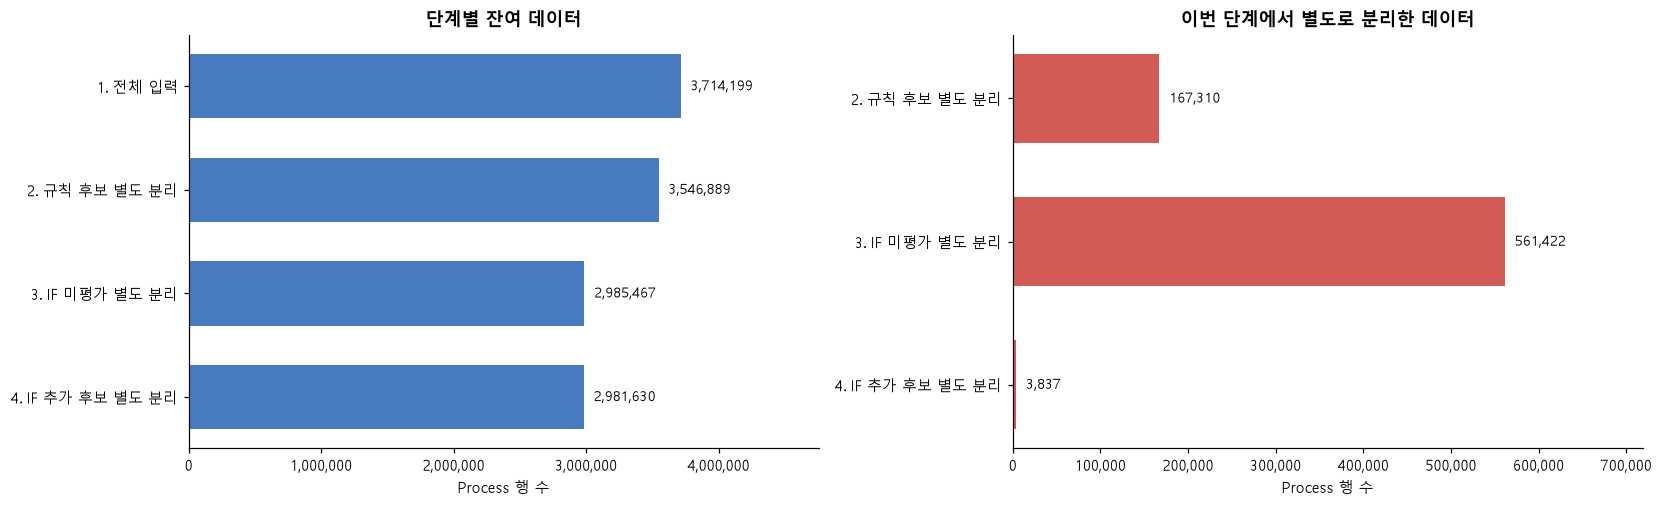

In [4]:
display(flow_table(result))
plot_flow(result)
plt.show()


In [5]:
display(Markdown(f"""
### 이 표에서 읽을 결론

원본 **{counts['input']:,}행**에서 규칙 후보 **{counts['rules']:,}행**을 별도 분리하면 **{counts['after_rules']:,}행**이 남는다.

그 잔여 중 **{counts['after_rules_unassessed']:,}행은 IF 미평가**다. 평가 가능한 **{counts['after_rules_assessed']:,}행**에서 IF가 추가로 잡은 것은 **{counts['if_only']:,}행**이다.

전체 IF 후보 **{counts['if_all']:,}행** 중 **{counts['both']:,}행은 규칙과 중복**된다. 따라서 최종 후보는
**규칙 {counts['rules']:,} + IF 추가 {counts['if_only']:,} = {counts['candidates']:,}행**이다.
규칙 후보 수와 IF 후보 수를 그대로 더하면 중복 계산이다.
"""))



### 이 표에서 읽을 결론

원본 **3,714,199행**에서 규칙 후보 **167,310행**을 별도 분리하면 **3,546,889행**이 남는다.

그 잔여 중 **561,422행은 IF 미평가**다. 평가 가능한 **2,985,467행**에서 IF가 추가로 잡은 것은 **3,837행**이다.

전체 IF 후보 **7,110행** 중 **3,273행은 규칙과 중복**된다. 따라서 최종 후보는
**규칙 167,310 + IF 추가 3,837 = 171,147행**이다.
규칙 후보 수와 IF 후보 수를 그대로 더하면 중복 계산이다.


### 1-1. 어떤 규칙에서 얼마나 줄었나?

**독립 탐지 행**은 다른 규칙과 무관하게 그 규칙이 True인 행이다. **이번 단계 추가 분리**는 앞 규칙에서 이미 잡힌 행을 제외한 수다. “단계 후 잔여”를 위에서 아래로 읽으면 규칙별 감소를 볼 수 있다.

순서는 요청한 규칙 목록에 맞춘 보고서 집계 순서다. 순서를 바꾸면 추가 분리 수는 바뀔 수 있지만, 전체 규칙 후보 합집합과 독립 탐지 수는 바뀌지 않는다. NA는 판단 불가이므로 탐지/제거로 세지 않는다.

P99/P99.9는 함께 “통계 꼬리” 한 규칙으로 묶고, 입력 파싱·정의 외 상태·PK 충돌 안전검사를 추가로 표시한다. **P99 초과는 확정 장애가 아니라 드문 값 후보**다.


,순서,규칙,독립 탐지 행,이번 단계 추가 분리,앞 단계와 중복,단계 후 잔여 행,단계 전 미평가 행,단계 전 행
0,1,실패 상태 F,132785,132785,0,3581414,0,3714199
1,2,부모 S / 기대 단계 전부 F,1,0,1,3581414,570828,3581414
2,3,부모 기대 단계 수 불일치,5479,5381,98,3576033,12130,3581414
3,4,성공 S인데 오류 건수 존재,10,10,0,3576023,562869,3576033
4,5,전체 ≠ 성공 + 오류 건수,26,12,14,3576011,562214,3576023
5,6,완료 상태인데 종료시각 결측,25,10,15,3576001,562214,3576011
6,7,SQL 필수 컬럼 결측,0,0,0,3576001,0,3576001
7,8,종료시각이 시작보다 앞섬,0,0,0,3576001,562213,3576001
8,9,건수·재시도 음수/소수,0,0,0,3576001,0,3576001
9,10,고정 P99/P99.9 초과,29393,29112,281,3546889,0,3576001


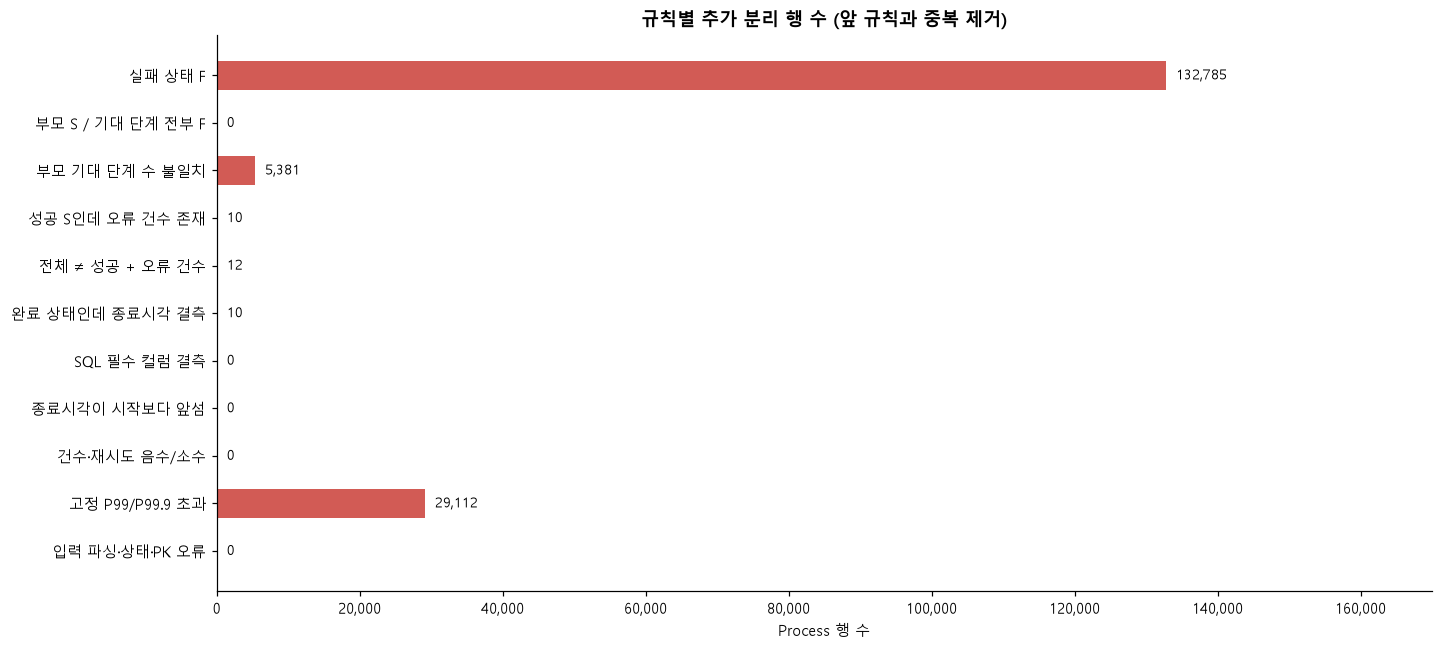

In [6]:
removals = rule_removal_table(result)
display(removals)
plot_rule_removals(result)
plt.show()


### 1-2. 기간별·전체 24개 Adapter별 전후 비교

각 행은 별도의 집단이다. “규칙 후 잔여 = 잔여 IF 평가 + 잔여 IF 미평가”이고, “최종 OR 후보 = 규칙 후보 + IF 추가 후보”다. 작은 Adapter도 생략하지 않는다.


In [7]:
display(Markdown("#### 기간별"))
display(group_filter_counts(result))
display(Markdown("#### Adapter별 — 원본 수 내림차순"))
adapter_flow = group_filter_counts(result, "adapterType").sort_values("원본 행", ascending=False)
display(adapter_flow)
assert adapter_flow["원본 행"].sum() == len(p)
assert adapter_flow["최종 OR 후보"].sum() == counts["candidates"]


#### 기간별

,source_period,원본 행,규칙 후보,규칙 후 잔여,잔여 IF 평가,잔여 IF 미평가,IF 추가 후보,최종 OR 후보
0,25년12월24일-26년4월6일,3473285,34095,3439190,2877904,561286,3254,37349
1,26년8월15일-26년9월14일,213509,131919,81590,81454,136,583,132502
2,26년9월30일-26년10월2일,27405,1296,26109,26109,0,0,1296


#### Adapter별 — 원본 수 내림차순

,adapterType,원본 행,규칙 후보,규칙 후 잔여,잔여 IF 평가,잔여 IF 미평가,IF 추가 후보,최종 OR 후보
8,DB.READER,1639795,15672,1624123,1411995,212128,2006,17678
10,DB.WRITER,1627833,15484,1612349,1411739,200610,1259,16743
22,SERVICE.EXECUTOR,282953,133577,149376,109899,39477,571,134148
15,GATEWAY.INVOKER,57285,50,57235,18,57217,0,50
7,DB.EXECUTOR,27271,438,26833,4476,22357,0,438
13,FILE.WRITER,25498,1148,24350,22445,1905,0,1148
12,FILE.READER,25477,466,25011,24504,507,1,467
21,QUEUE.SUBSCRIBER,13091,160,12931,47,12884,0,160
19,QUEUE.EXECUTOR,13087,161,12926,53,12873,0,161
20,QUEUE.PUBLISHER,1152,18,1134,9,1125,0,18


### 1-3. “규칙 후 잔여”와 “모델 학습 후보”는 다르다

위는 **전체 기간 추론 결과**이고, 아래는 **과거 train 학습 집단의 선택 과정**이다. 이 구현은 규칙에 안 걸린 모든 상태를 학습하는 것이 아니라 **S만 정상의 대용 집단으로 선택**한다. 따라서 N을 학습에서 빼는 것은 “N을 이상으로 판정했다”는 뜻이 아니다.

전체 → 과거 train → S → 유효 시간·품질 → 정합성 제외 → 통계 꼬리 제외를 서로 겹치지 않게 센다. 최종 후보 중 실제 GLOBAL fit에는 최대 100,000행의 Adapter 균형 표본을 사용했다.


In [8]:
display(training_filter_table(p, result, split, pipeline))
display(adapter_training_counts(p, result, split, pipeline))
print(f"GLOBAL 학습 후보 {pipeline.global_model.support['train_rows']:,}행 → 실제 fit 표본 {pipeline.global_model.support['train_sample_rows']:,}행")


,학습 단계,단계 전 행,이번 단계 제외,남은 학습 후보
0,과거 train만 선택,3714199,538547,3175652
1,S만 학습 후보로 선택,3175652,567157,2608495
2,유효 완료시간·품질 조건,2608495,13,2608482
3,정합성 후보 제외,2608482,30,2608452
4,통계 꼬리 후보 제외,2608452,26073,2582379


,Adapter,세 기간 원본,원본 train,train N,train S,최종 학습 후보
8,DB.READER,1639795,1493858,214061,1279555,1266772
10,DB.WRITER,1627833,1481635,202041,1279444,1266649
22,SERVICE.EXECUTOR,282953,42436,39741,2660,2621
15,GATEWAY.INVOKER,57285,57248,57216,3,3
7,DB.EXECUTOR,27271,22782,22779,2,2
13,FILE.WRITER,25498,25039,611,22360,22136
12,FILE.READER,25477,25038,496,24414,24151
21,QUEUE.SUBSCRIBER,13091,13038,13028,4,1
19,QUEUE.EXECUTOR,13087,13035,13025,9,2
20,QUEUE.PUBLISHER,1152,1140,1138,2,2


GLOBAL 학습 후보 2,582,379행 → 실제 fit 표본 100,000행


## 2. 전체 데이터 분포와 실제 P99/P99.9 threshold

### 2-1. 규칙 전 전체 vs 규칙 후보 분리 후

세 기간의 **모든 행**을 대상으로 처리시간·처리건수·재시도를 비교한다. 표와 막대는 표본이 아니라 전수다. 결측·무효 값은 0으로 채우지 않고 “유효값 행” 분모에서 제외한다. 처리시간 단위는 초다. **유효 수치 분모와 IF 평가 분모는 다르다.** 예를 들어 N/P라도 시작·종료 시각이 모두 있으면 수치 분포에는 들어가지만 IF의 완료 상태 조건은 만족하지 않는다.

표의 **관측 P99/P99.9는 현재 집단의 요약값**이다. 탐지에 사용한 과거 고정 threshold와 다르다. 규칙 후보를 분리한 뒤 꼬리가 줄어드는 것은 필터 선택 효과이며 모델이 좋아졌다는 증거는 아니다.

막대의 x축은 실제 단위 구간, y축은 유효값 중 비중이다. 구간 폭이 서로 달라 확률밀도가 아니다. 마지막 “이상” 구간에 큰 값을 모두 포함한다. 각 행의 좌우 그림은 같은 y축 범위로 비교한다.


,집단,변수,단위,집단 전체 행,유효값 행,결측·무효 행,중앙값,관측 P95,관측 P99,관측 P99.9,최댓값
0,규칙 적용 전 전체,처리시간,초,3714199,3146616,567583,0.619,8.699,9.655,19.579385,"1,802.839"
1,규칙 적용 전 전체,처리건수,건,3714199,3714194,5,"10,000","10,000","10,485,760","10,485,760","524,288,000"
2,규칙 적용 전 전체,재시도,회,3714199,3714199,0,0,0,0,0,0
3,규칙 후보 분리 후,처리시간,초,3546889,2985468,561421,0.711,8.66,9.466,10.134,24.217
4,규칙 후보 분리 후,처리건수,건,3546889,3546884,5,"10,000","10,000","10,485,760","10,485,760","168,588,859"
5,규칙 후보 분리 후,재시도,회,3546889,3546889,0,0,0,0,0,0


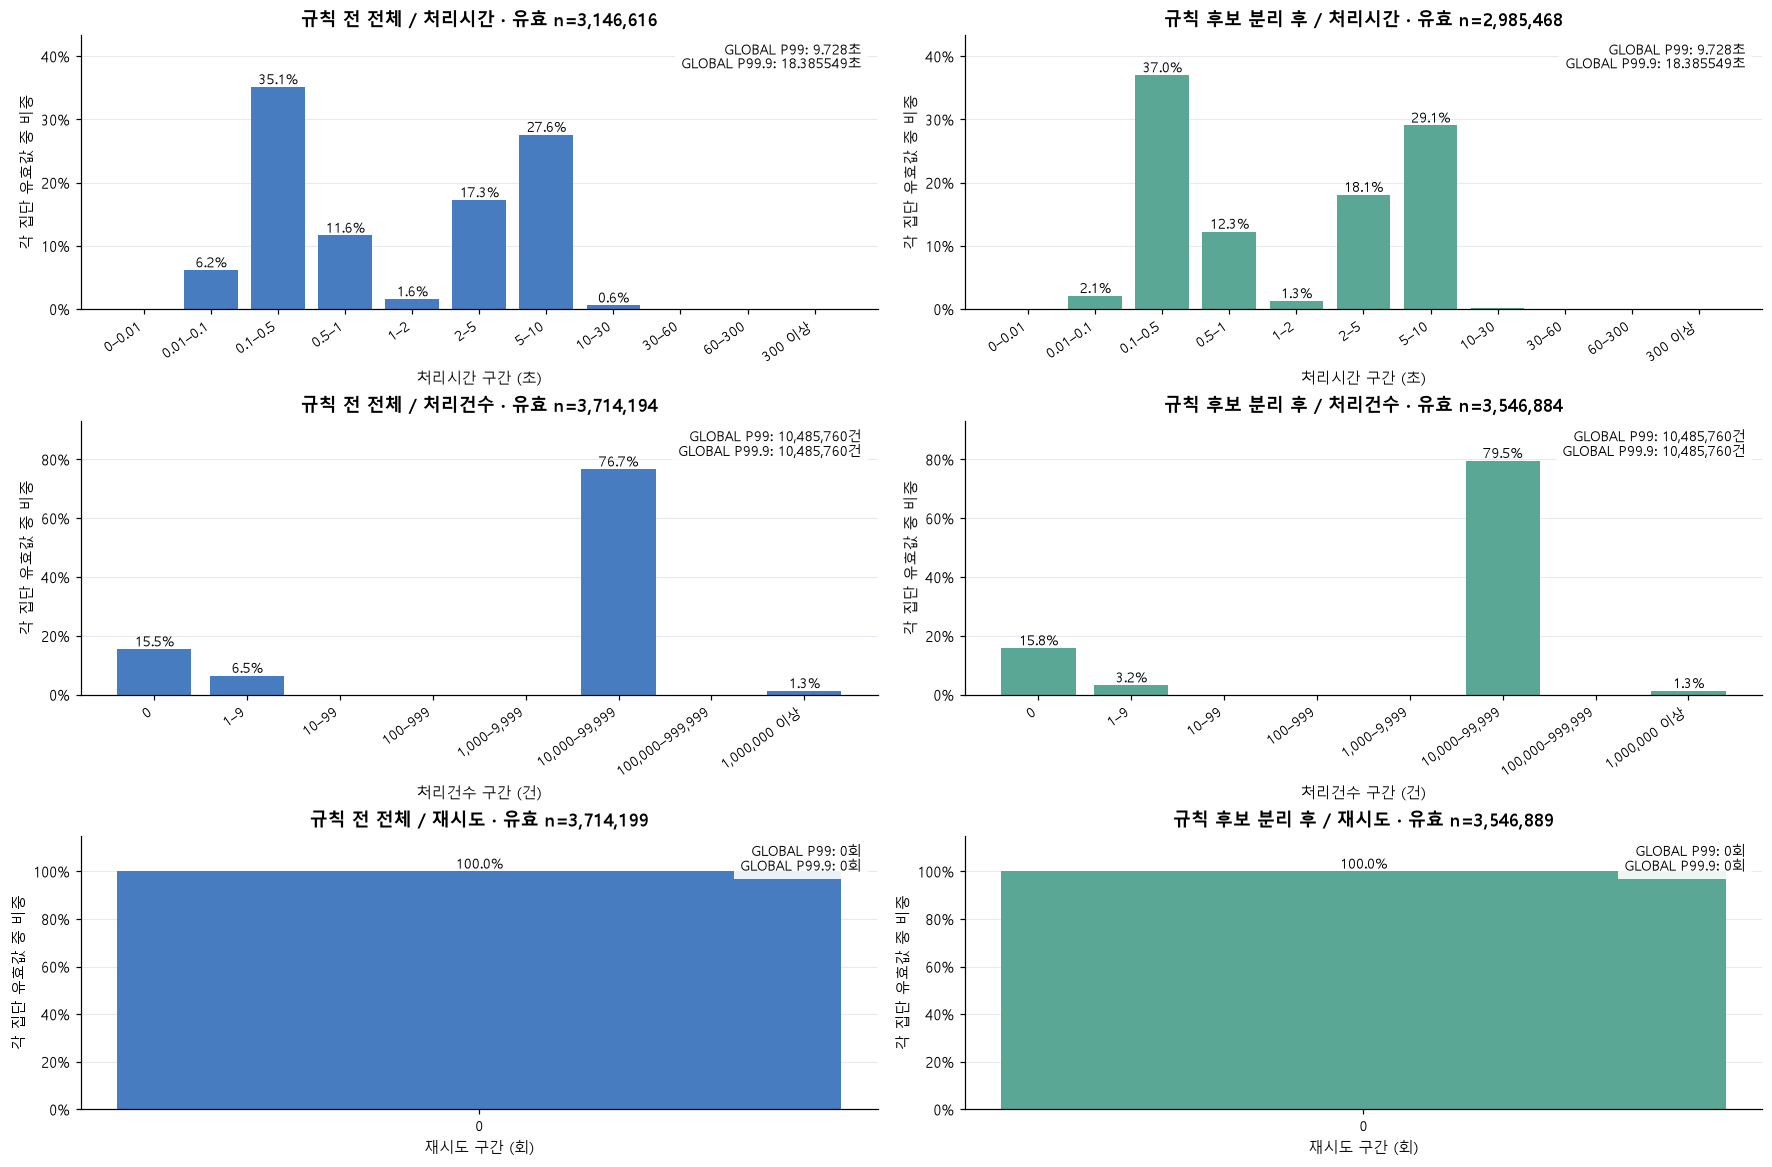

In [9]:
display(full_numeric_summary(p, result))
plot_full_inputs(p, result, pipeline)
plt.show()


### 2-2. 실제 탐지에 사용한 고정 threshold 값

아래는 **모델에 저장된 값**이다. 과거 train의 S·유효 시간·품질/정합성 미충족 집단에서 산정했고, 추론마다 재계산하지 않는다. 통계 꼬리 제외 전 집단에서 정했으므로 IF의 최종 학습 후보 수와 다를 수 있다.

Adapter 기준이 충분하면 그 Adapter의 기준을 쓰고, 부족하면 GLOBAL 기준을 쓴다. 이 기준 선택은 IF 전문가 생성 여부와 별개다. 예를 들어 전문가가 없는 FILE도 충분한 과거 데이터가 있으면 자체 P99를 가질 수 있다.

- **threshold:** 실제 판정 기준. 실측값이 엄격히 `>`일 때 후보이고 동률은 아니다.
- **과거 산정 행:** 기준을 정한 비결측 과거 데이터 수.
- **현재 평가 행:** 이번 전체 입력에서 해당 기준을 실제 사용하고 비교 가능했던 행 수.
- **초과 행:** 그 중 threshold를 넘은 수. P99/P99.9 중복 및 변수 간 중복이 있어 합산하지 않는다.

앞 그림의 GLOBAL 상자는 공통 참고값이다. **모든 행에 같은 GLOBAL 값을 적용했다는 의미가 아니다.** 아래 기준집단과 사례의 실제 basis를 확인한다. 같은 기준의 P99.9는 P99에 포함되지만 서로 다른 Adapter/GLOBAL 기준이면 포함 관계나 심각도 순서를 보장하지 않는다.


In [10]:
stat_cuts = statistical_threshold_table(result, pipeline)
for variable in stat_cuts["변수"].unique():
    display(Markdown(f"#### {variable} — 실제 고정 기준과 이번 평가 수"))
    display(stat_cuts.loc[stat_cuts["변수"].eq(variable)].reset_index(drop=True))


#### 처리시간 — 실제 고정 기준과 이번 평가 수

,변수,기준집단,분위수,threshold,단위,과거 산정 행,현재 평가 행,초과 행,초과 %
0,처리시간,GLOBAL,P99,9.728,초,2608452,5101,110,2.15644
1,처리시간,DB.READER,P99,1.127,초,1279550,1425440,13252,0.929678
2,처리시간,DB.WRITER,P99,10.402,초,1279442,1425271,13286,0.932174
3,처리시간,FILE.READER,P99,24.21754,초,24395,24939,324,1.29917
4,처리시간,FILE.WRITER,P99,1.55582,초,22360,22788,327,1.434966
5,처리시간,SERVICE.EXECUTOR,P99,7.11177,초,2648,243077,1295,0.532753
6,처리시간,GLOBAL,P99.9,18.385549,초,2608452,248178,448,0.180516
7,처리시간,DB.READER,P99.9,2.385,초,1279550,1425440,1373,0.096321
8,처리시간,DB.WRITER,P99.9,20.644031,초,1279442,1425271,1567,0.109944
9,처리시간,FILE.READER,P99.9,27.357908,초,24395,24939,105,0.421027


#### 처리건수 — 실제 고정 기준과 이번 평가 수

,변수,기준집단,분위수,threshold,단위,과거 산정 행,현재 평가 행,초과 행,초과 %
0,처리건수,GLOBAL,P99,"10,485,760",건,2608452,112638,0,0
1,처리건수,DB.READER,P99,"10,000",건,1279550,1639795,10,0.00061
2,처리건수,DB.WRITER,P99,"10,000",건,1279442,1627833,10,0.000614
3,처리건수,FILE.READER,P99,"168,588,859",건,24395,25477,1,0.003925
4,처리건수,FILE.WRITER,P99,"10,485,760",건,22360,25498,858,3.36497
5,처리건수,SERVICE.EXECUTOR,P99,1,건,2648,282953,0,0
6,처리건수,GLOBAL,P99.9,"10,485,760",건,2608452,395591,0,0
7,처리건수,DB.READER,P99.9,"10,000",건,1279550,1639795,10,0.00061
8,처리건수,DB.WRITER,P99.9,"10,000",건,1279442,1627833,10,0.000614
9,처리건수,FILE.READER,P99.9,"168,588,859",건,24395,25477,1,0.003925


#### 재시도 — 실제 고정 기준과 이번 평가 수

,변수,기준집단,분위수,threshold,단위,과거 산정 행,현재 평가 행,초과 행,초과 %
0,재시도,GLOBAL,P99,0,회,2608452,112643,0,0
1,재시도,DB.READER,P99,0,회,1279550,1639795,0,0
2,재시도,DB.WRITER,P99,0,회,1279442,1627833,0,0
3,재시도,FILE.READER,P99,0,회,24395,25477,0,0
4,재시도,FILE.WRITER,P99,0,회,22360,25498,0,0
5,재시도,SERVICE.EXECUTOR,P99,0,회,2648,282953,0,0
6,재시도,GLOBAL,P99.9,0,회,2608452,395596,0,0
7,재시도,DB.READER,P99.9,0,회,1279550,1639795,0,0
8,재시도,DB.WRITER,P99.9,0,회,1279442,1627833,0,0
9,재시도,FILE.READER,P99.9,0,회,24395,25477,0,0


**분포의 의미:** 처리시간은 업무/Adapter 특성과 함께 읽어야 한다. 처리건수의 긴 꼬리는 대량 정상 배치일 수도 있으므로 초과만으로 장애를 확정하지 않는다. 재시도가 거의 모두 0이면 이 변수는 기존 학습에서 구분력이 작다. 새로운 양수 재시도는 통계 기준에 걸릴 수 있지만, IF가 이를 반드시 학습해 잡는다는 보장은 없다.

특히 N/P의 종료 시각이 없는 행을 처리시간 0으로 보거나, IF 미평가를 “모델이 정상으로 판단했다”고 해석하면 안 된다.


## 3. 전체 IF 점수 분포와 threshold 선

### 3-1. 실제 판정 규칙과 경로별 값

IF 입력은 Process의 처리시간·처리건수·재시도, 결측 표시, 시작 시간의 시간대·요일 순환 피처다. STATUS·ID·성공/오류 건수는 IF 피처가 아니다.

원시 점수는 `-score_samples`이며 큰 값일수록 학습 패턴에서 드물다. calibration 집단에서 모델별 중앙값·P95 간격으로 점수 단위를 맞춘다. 준비된 Adapter는 GLOBAL과 Adapter의 정규화 점수를 가중 평균하고, 부족/새 Adapter는 GLOBAL만 쓴다. 이 점수는 **이상 확률이 아니다.**

판정은 **최종 점수 > 해당 경로 threshold**다. 아래 threshold는 독립 threshold 집단의 S 정상 대용 데이터에서 정한 P99다. “상위 약 1% 검토”라는 초기 정책이지 최적값이나 실제 이상 비율이라는 뜻은 아니다. GLOBAL-only 판정선은 fallback 행만이 아니라 **전체 Adapter의 threshold 기준집단 GLOBAL 점수**에서 산정했다.


In [11]:
display(Markdown(f"현재 앙상블: GLOBAL **{pipeline.config.global_weight:g}** + Adapter **{1-pipeline.config.global_weight:g}**"))
display(route_threshold_table(result, pipeline))


현재 앙상블: GLOBAL **0.5** + Adapter **0.5**

,판정 경로,사용 점수,threshold,판정선 산정 S 행,현재 IF 평가 행,IF 후보 행,규칙 미탐지 IF 추가
0,GLOBAL,GLOBAL만,1.274851,183239,52827,11,1
1,DB.READER,GLOBAL + Adapter 가중 평균,0.697132,72480,1425440,4076,2006
2,DB.WRITER,GLOBAL + Adapter 가중 평균,0.704782,72404,1425271,1325,1259
3,SERVICE.EXECUTOR,GLOBAL + Adapter 가중 평균,1.0551,35973,243077,1698,571


### 3-2. 전체 평가 행을 하나의 그림으로 읽는 방법

Adapter마다 threshold가 달라 전체 데이터에 임의의 공통 점수 판정선을 그리지 않는다. 대신 각 행에 적용한 실제 threshold를 빼서 **초과폭(margin)**으로 맞춘다.

`초과폭 = 최종 IF 점수 - 해당 행의 실제 경로 threshold`

**빨간 점선 0보다 오른쪽이면 IF 후보**, 왼쪽/동률이면 IF 미탐지다. 옅은 붉은 배경은 후보 영역이다. 왼쪽은 규칙 후보 포함 전체 IF 평가 행, 오른쪽은 규칙 미탐지 집단만의 IF 평가 행이다. 두 그림 모두 전수 히스토그램이며 같은 축 범위를 사용한다.

IF 미평가 행은 점수가 없어 이 분포에 들어갈 수 없다. 그 수는 1절에 따로 제시했다. 음수 margin은 확인된 정상이나 안전을 뜻하지 않고, Adapter 간 margin 크기는 보장된 위험도 순위가 아니다.


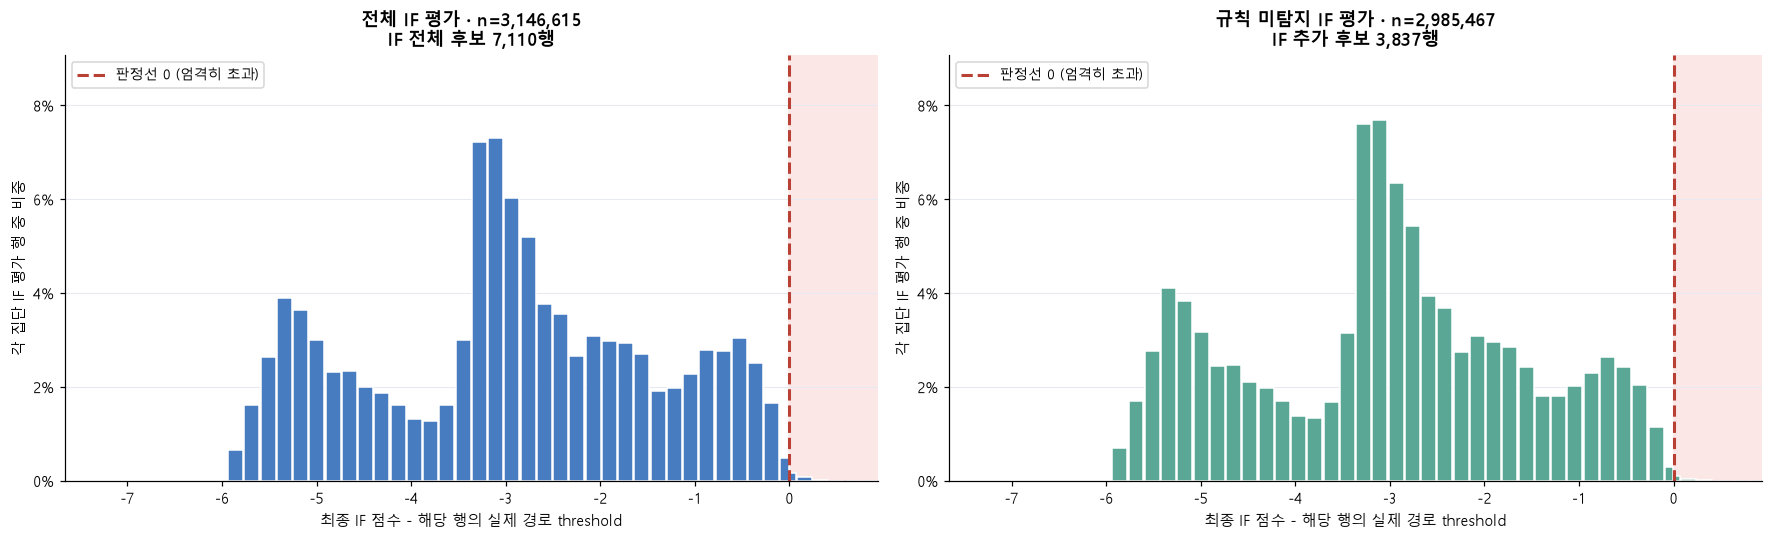

In [12]:
plot_full_score_margins(result)
plt.show()


### 3-3. 실제 점수 좌표로 보는 경로별 판정선

앞 그림의 0선이 원래 점수에서는 얼마인지 아래 빨간 점선과 3-1 표로 연결한다. threshold 구간과 미래 test를 경로별로 분리한다. 각 그림에 **전체 n / 그림 표본 n**을 적었으며, 표의 집계는 표본이 아니다.

GLOBAL 패널의 fallback 분포는 GLOBAL 판정선을 산정한 전체 Adapter 기준집단과 다르다. 과거 train/validation에서의 반응과 미래 test에서의 반응을 구분해서 읽는다.


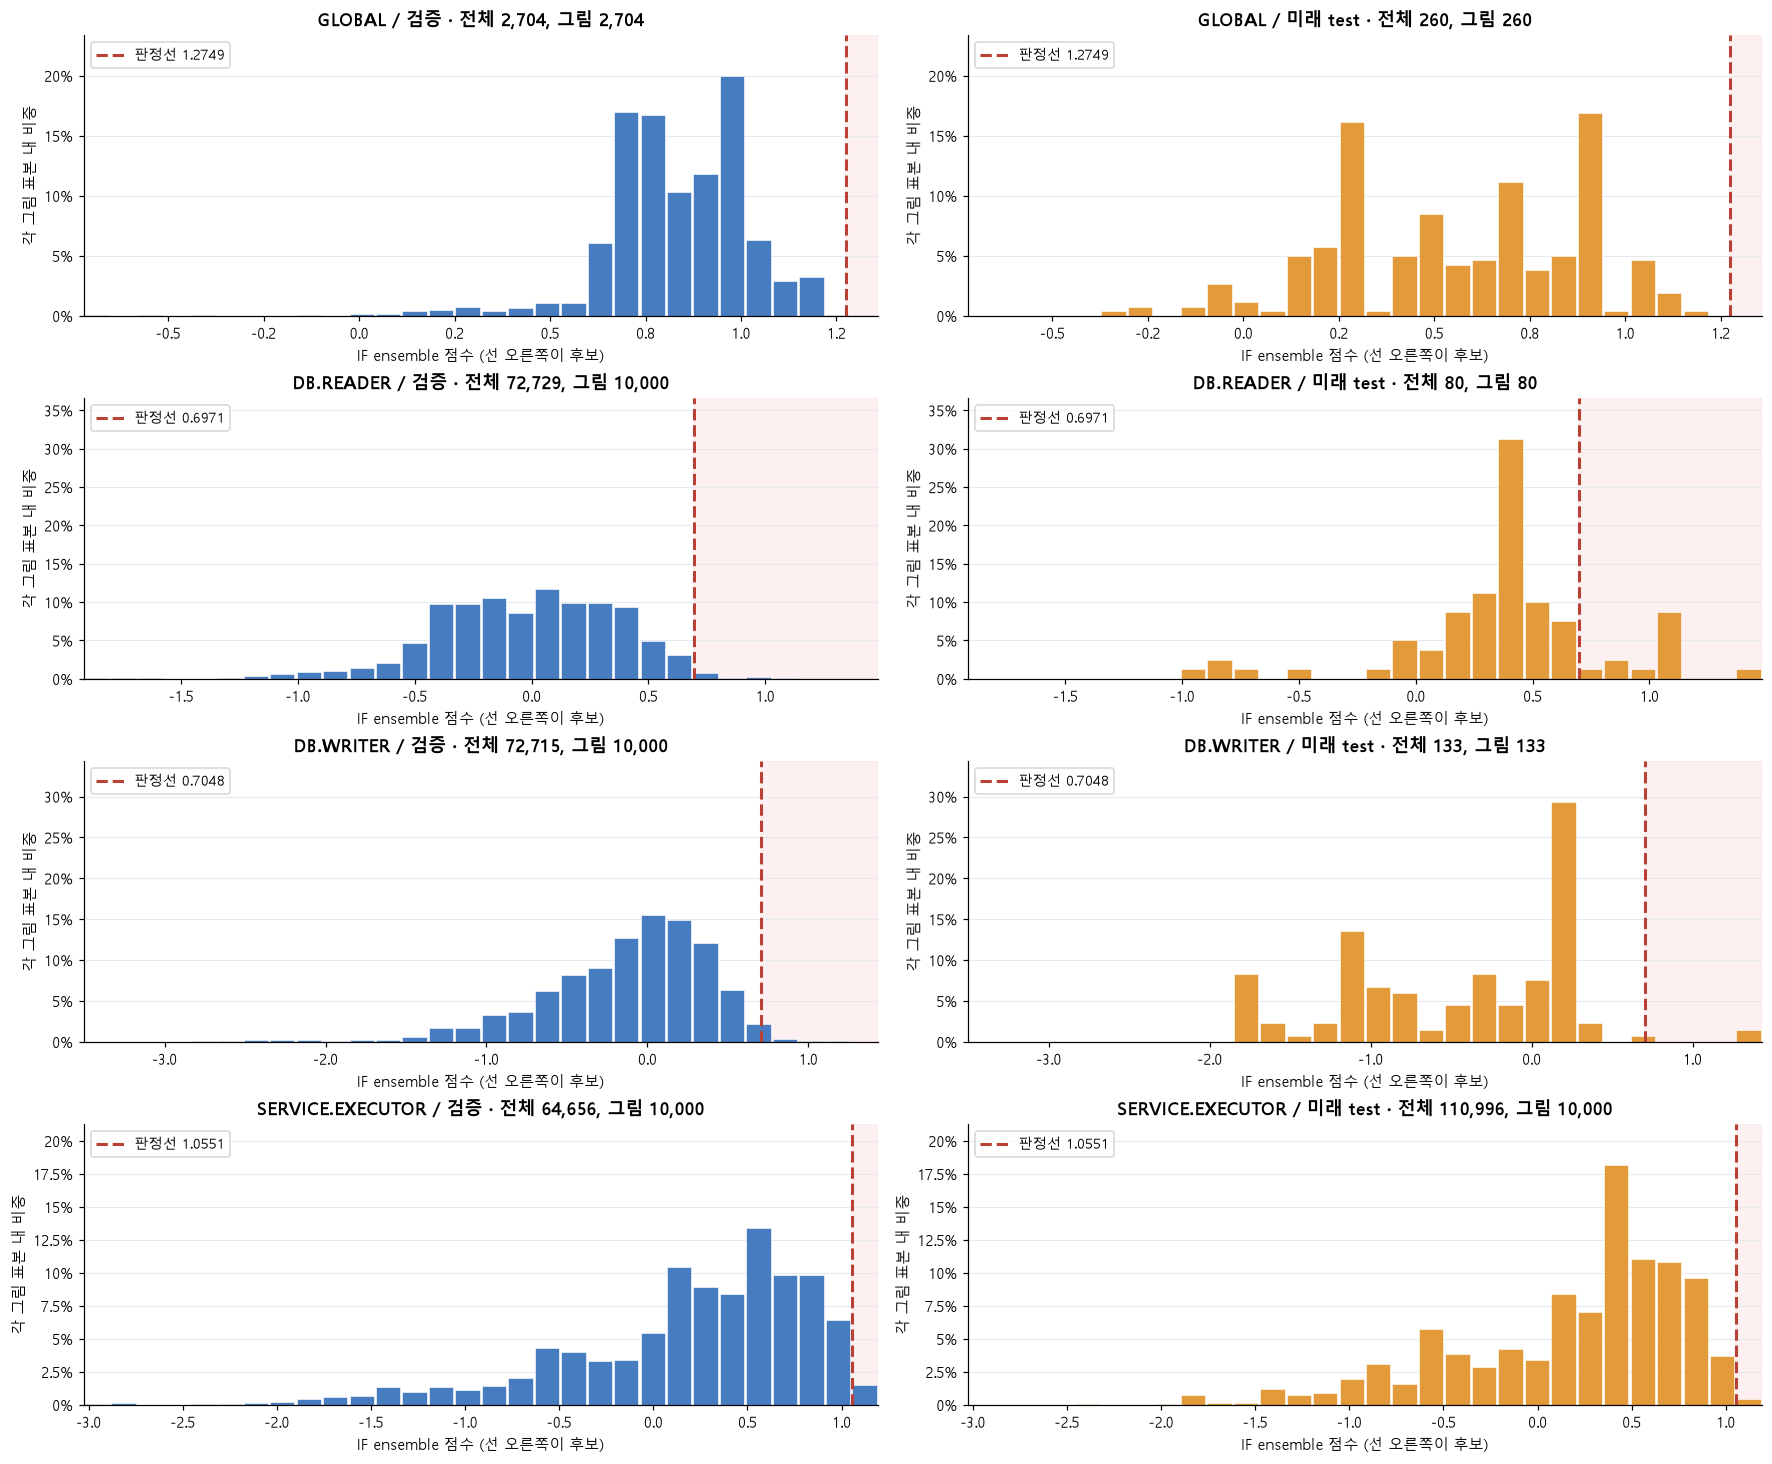

In [13]:
plot_model_scores(result, split, pipeline, reference_only=False)
plt.show()


## 4. 최종 탐지 결과 — 중복과 미평가를 분리해서 보기

아래 다섯 집단은 서로 겹치지 않고 합계가 원본 행 수와 같다. 규칙과 IF가 잡는 대상은 다를 수 있다. F는 처리 실패의 명시적 기록이고, IF는 수치/시간 문맥의 드문 패턴을 찾는다. **IF가 F를 전부 다시 잡아야 한다는 전제로 평가하지 않는다.**


,구분,행 수,전체 입력 중 %
0,규칙만 후보,164037,4.416484
1,규칙과 IF 모두 후보,3273,0.088121
2,IF만 추가 후보,3837,0.103306
3,둘 다 미탐지 / IF 평가,2981630,80.276528
4,규칙 미탐지 / IF 미평가,561422,15.115561


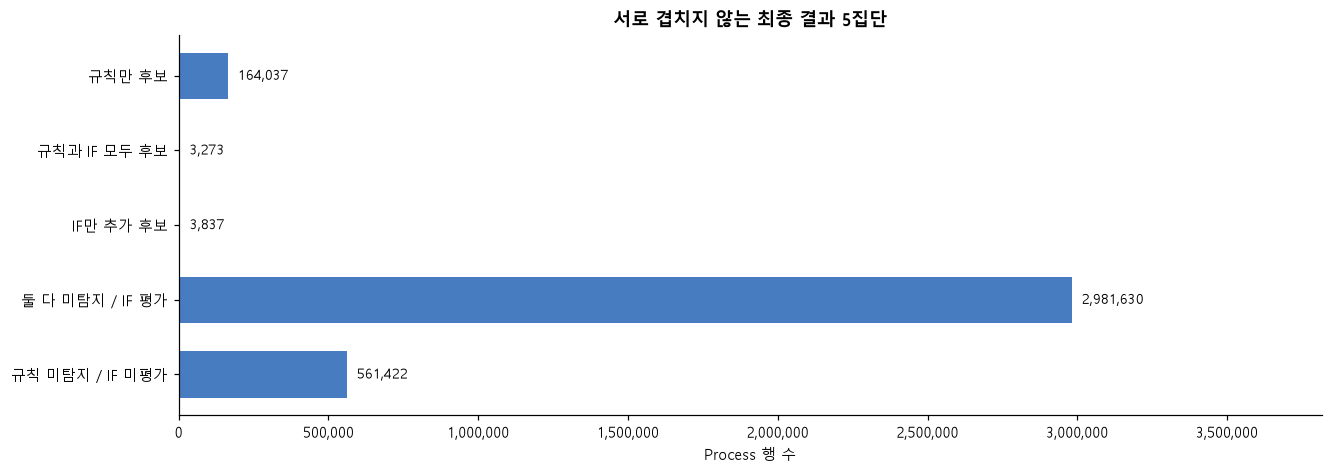

In [14]:
display(partition_table(result))
plot_partitions(result)
plt.show()


### 4-1. STATUS별·미래 test 결과

STATUS별 표에서 **전체 행**과 **IF 평가 행**이 다르다는 점을 먼저 본다. IF 비율의 분모는 평가 행이며, 0개 평가 집단의 비율은 결측/미평가다. 최종 후보 비율의 분모는 전체 행이다. N/P가 자동으로 정상인 것도, 전부 이상인 것도 아니다.

미래 test는 학습/판정선 산정 이후의 데이터다. 아래 숫자는 후보 수와 비율이지 정확도·재현율·오탐률이 아니다.


#### 전체 기간 STATUS별

,status,전체_행,IF_평가_행,규칙_후보,IF_후보,최종_후보,명시적_실패,품질_오류,IF 후보 / 평가 행 %,최종 후보 / 전체 행 %,IF 미평가 행
0,F,132785,132775,132785,1279,132785,132785,0,0.963284,100,10
1,H,37,37,9,3,10,0,0,8.108108,27.027027,0
2,N,565464,0,5332,0,5332,0,0,<NA>,0.942942,565464
3,P,2095,0,805,0,805,0,0,<NA>,38.424821,2095
4,S,3013199,3013184,28366,5795,32175,0,0,0.192321,1.067802,15
5,Z,619,619,13,33,40,0,0,5.331179,6.462036,0


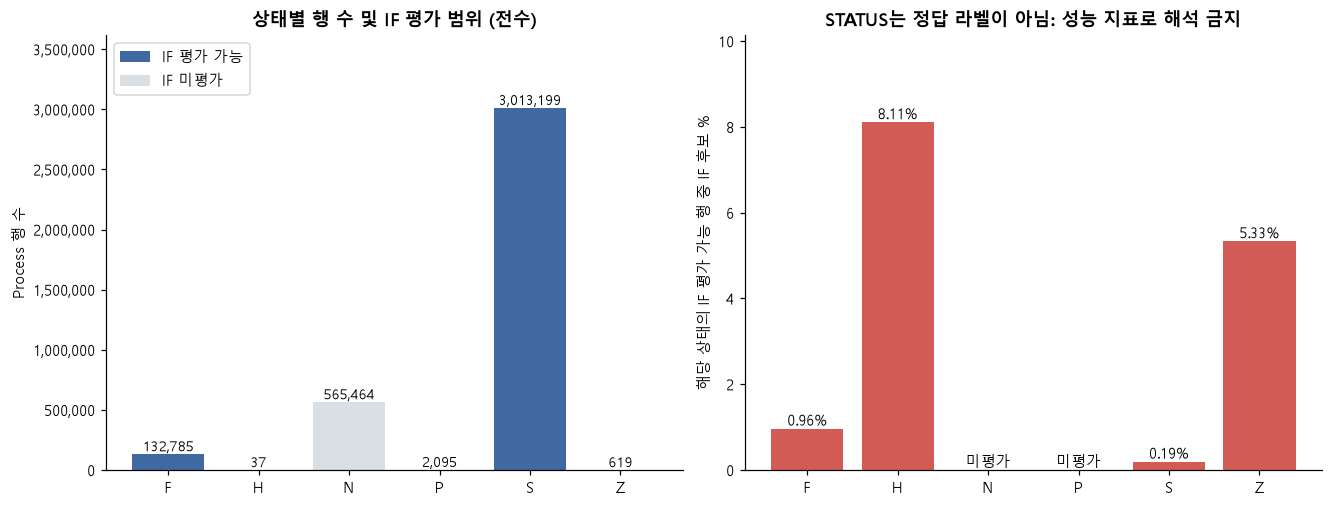

#### 미래 test / Adapter별

,adapterType,전체_행,IF_평가_행,규칙_후보,IF_후보,최종_후보,명시적_실패,품질_오류,IF 후보 / 평가 행 %,최종 후보 / 전체 행 %,IF 미평가 행
18,SERVICE.EXECUTOR,111076,110996,75537,470,75609,74298,0,0.423439,68.06961,80
6,DB.WRITER,133,133,52,3,54,50,0,2.255639,40.601504,0
5,DB.READER,80,80,11,12,20,3,0,15,25,0
15,QUEUE.EXECUTOR,42,42,0,0,0,0,0,0,0,0
17,QUEUE.SUBSCRIBER,42,42,0,0,0,0,0,0,0,0
8,FILE.READER,39,39,9,0,9,3,0,0,23.076923,0
9,FILE.WRITER,33,33,18,0,18,3,0,0,54.545455,0
19,SERVICE.INVOKER,25,25,8,0,8,8,0,0,32,0
1,DATA.MAPPER,21,21,7,0,7,7,0,0,33.333333,0
2,DATA.TRANSFORMER,12,12,2,0,2,0,0,0,16.666667,0


#### 미래 test / STATUS별

,status,전체_행,IF_평가_행,규칙_후보,IF_후보,최종_후보,명시적_실패,품질_오류,IF 후보 / 평가 행 %,최종 후보 / 전체 행 %,IF 미평가 행
0,F,74386,74386,74386,400,74386,74386,0,0.537736,100,0
1,H,2,2,0,0,0,0,0,0,0,0
2,N,80,0,0,0,0,0,0,<NA>,0,80
3,S,36987,36987,1287,84,1370,0,0,0.227107,3.704004,0
4,Z,94,94,1,1,1,0,0,1.06383,1.06383,0


In [15]:
display(Markdown("#### 전체 기간 STATUS별"))
display(outcome_summary(result, "status"))
plot_status(result)
plt.show()
display(Markdown("#### 미래 test / Adapter별"))
display(outcome_summary(result.loc[test], "adapterType").sort_values("전체_행", ascending=False))
display(Markdown("#### 미래 test / STATUS별"))
display(outcome_summary(result.loc[test], "status"))


### 4-2. 일별 후보 변화

막대가 높아진 날짜의 원본 행 수·상태 구성·Adapter 구성을 함께 확인한다. 규칙 비율과 IF 비율은 분모가 다르므로 같은 높이가 같은 행 수를 의미하지 않는다. **1행 중 1행 후보인 100%와 10만 행 중 10만 행 후보인 100%는 다르다.** 아래 표의 `rows`(시작시각 있는 원본), `assessed`(IF 평가), `model`(IF 후보), `rules`(규칙 후보)를 함께 본다. 관측이 없는 날을 정상 0건으로 채우지 않는다. 이후 날짜의 분포 변화는 모델 드리프트/업무량 변화의 검토 근거이지 원인 확정이 아니다.


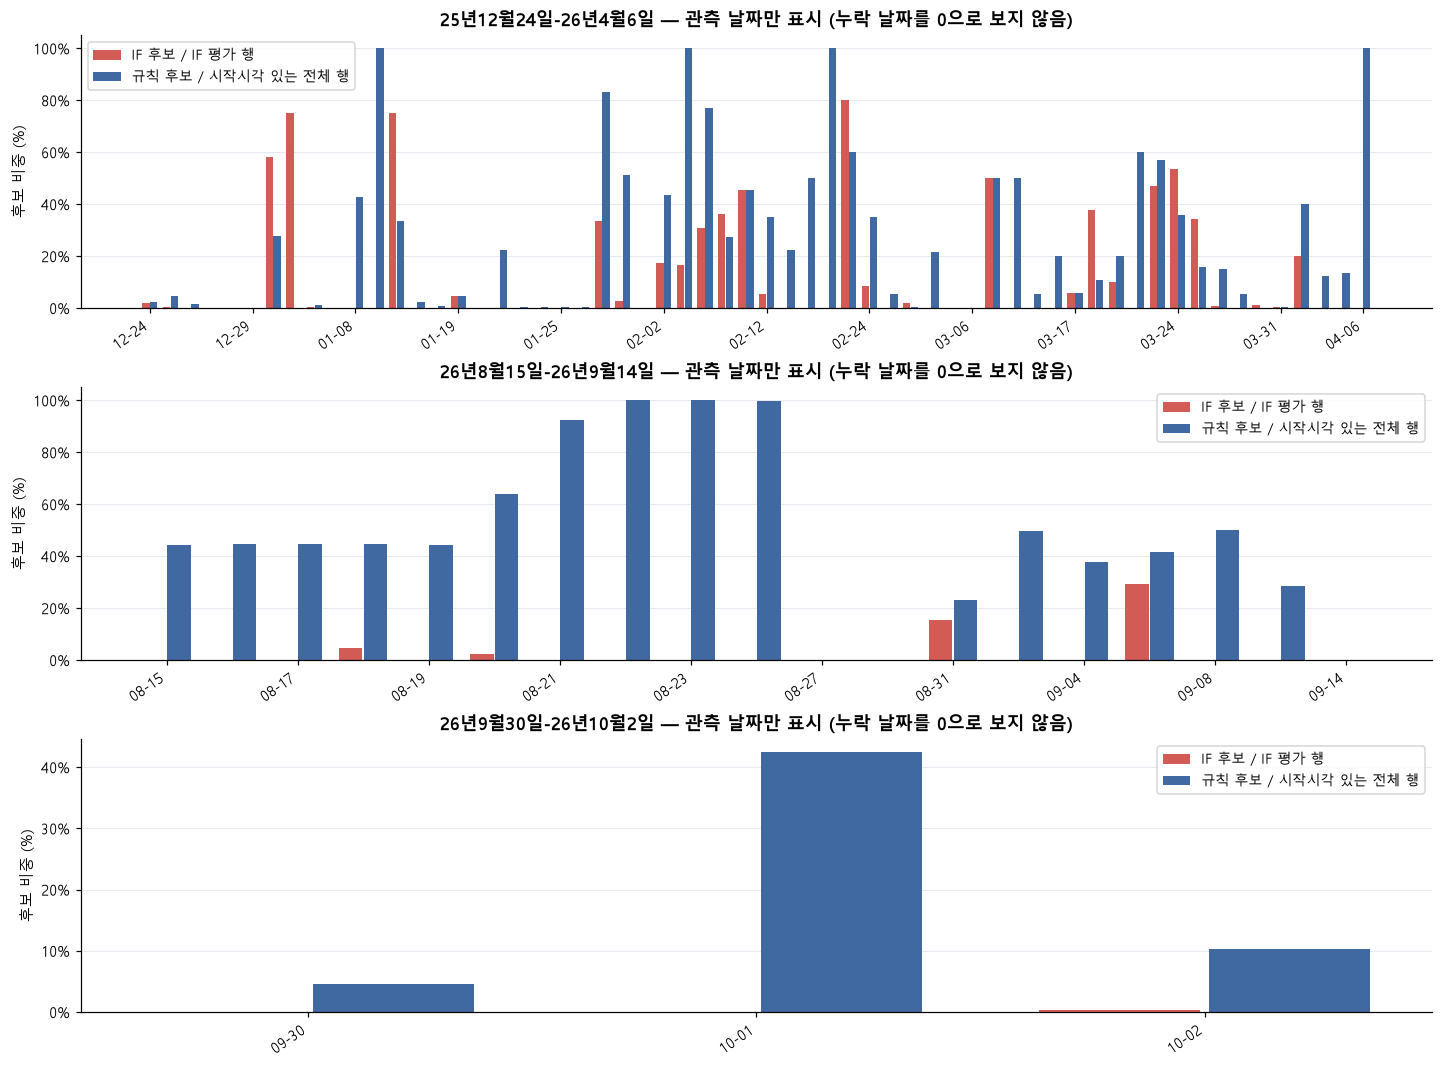

,day,rows,assessed,model,rules,IF 후보 %,규칙 후보 %,period
34,2026-02-23,10,10,8,6,80,60,25년12월24일-26년4월6일
12,2026-01-14,12,12,9,4,75,33.333333,25년12월24일-26년4월6일
7,2025-12-31,4,4,3,0,75,0,25년12월24일-26년4월6일
6,2025-12-30,36,36,21,10,58.333333,27.777778,25년12월24일-26년4월6일
50,2026-03-24,95,95,51,34,53.684211,35.789474,25년12월24일-26년4월6일
41,2026-03-11,2,2,1,1,50,50,25년12월24일-26년4월6일
49,2026-03-23,79,79,37,45,46.835443,56.962025,25년12월24일-26년4월6일
29,2026-02-11,11,11,5,5,45.454545,45.454545,25년12월24일-26년4월6일
46,2026-03-18,66,61,23,7,37.704918,10.606061,25년12월24일-26년4월6일
28,2026-02-10,11,11,4,3,36.363636,27.272727,25년12월24일-26년4월6일


In [16]:
fig, daily = plot_daily(result, p, split)
plt.show()
display(daily.sort_values("IF 후보 %", ascending=False).head(12))


## 5. 실제 탐지 사례 — 무엇이 기준을 넘었나?

아래는 **실제 후보 행**이다. 1절의 전체 추론 결과에서 사례만 선택해 설명하므로, 사례 몇 개만으로 Process 수나 부모 상태를 다시 추정하지 않는다.

각 사례는 식별자 → 입력값 → **실측값 vs 판정 조건** → 모델 점수 순서로 읽는다. IF만 잡은 사례는 과거 같은 Adapter/GLOBAL 분포와 추가 비교한다. 사례는 규칙별 대표 1행 및 미래 test의 IF-only 초과폭 상위 2행이며, 무작위 표본이나 모든 후보의 대표 비율은 아니다.

**“왜 판정됐나”와 “실제 장애의 원인이 무엇인가”는 다르다.** 규칙의 논리 조건과 IF 점수 초과는 정확히 설명할 수 있다. 피처 분포 비교는 맥락 설명이며 IF의 기여도/SHAP이나 인과 설명이 아니다.


In [17]:
rule_ids, model_ids = select_case_indices(result, split)
chosen_ids = list(dict.fromkeys(rule_ids + model_ids))
items = pipeline.explain(p.loc[chosen_ids], result=result.loc[chosen_ids])
case_by_id = dict(zip(chosen_ids, items))

def show_case(idx, title, with_profile=False):
    item, source = case_by_id[idx], p.loc[idx]
    display(Markdown(
        f"### {title}\n\n"
        f"기간: {item['source_period']} / Adapter: **{item['adapterType']}** / 분할: {split.loc[idx]}\n\n"
        f"Transaction: {item['transactionId']}\n\n"
        f"Process: {item['processId']} / Hub: {item['processHubId']} / 재시도: {item['retryCount']}"
    ))
    inputs = [("STATUS", source.status), ("시작", source.startTime), ("종료", source.endTime),
              ("처리시간(초)", source.duration_ms / 1000), ("전체 건수", source.totalCount),
              ("성공 건수", source.successCount), ("오류 건수", source.errorCount)]
    display(pd.DataFrame(inputs, columns=["입력 항목", "실제 값"]))
    display(Markdown("**탐지 이유 — 이 조건을 실제로 만족했다**"))
    display(case_evidence_table(item))
    model = item["model"]
    if model["ensemble_score"] is not None:
        display(pd.DataFrame([
            ("모델 경로", model["route"]), ("GLOBAL 정규화 점수", model["global_normalized_score"]),
            ("Adapter 정규화 점수", model["adapter_normalized_score"]),
            ("최종 점수", model["ensemble_score"]), ("적용 threshold", model["threshold"]),
            ("초과폭", model["margin"]), ("IF 판정", "후보" if model["margin"] > 0 else "미탐지"),
        ], columns=["모델 항목", "실제 값"]))
    else:
        display(Markdown("IF **미평가**: 유효 완료 시각/품질 조건을 만족하지 않아 점수를 계산하지 않았다."))
    if with_profile:
        display(Markdown("**과거 분포와 비교 — 원인 기여도가 아닌 참고 맥락**"))
        display(case_feature_table(item))
        display(Markdown(case_context_text(item)))
        display(Markdown(
            f"시작 시간대 **{source.startTime.hour}시**, 요일 **{source.startTime.day_name()}**도 IF 입력에 포함된다. "
            "수치 하나가 P99를 넘지 않아도 여러 피처의 조합이 드물면 IF 후보가 될 수 있다."
        ))
    if item["unevaluated_rules"]:
        display(Markdown("미평가 규칙: " + ", ".join(RULE_LABELS[name] for name in item["unevaluated_rules"])))
    display(Markdown("---"))

print(f"규칙 대표 {len(rule_ids)}행 / IF-only 대표 {len(model_ids)}행")
display(result.loc[chosen_ids, ["source_period", "adapterType", "status", "rule_candidate",
                              "model_candidate", "ensemble_score", "model_threshold", "score_margin"]])


규칙 대표 6행 / IF-only 대표 2행


,source_period,adapterType,status,rule_candidate,model_candidate,ensemble_score,model_threshold,score_margin
0,25년12월24일-26년4월6일,DB.WRITER,F,True,True,1.117318,0.704782,0.412536
3473326,26년8월15일-26년9월14일,SERVICE.INVOKER,F,True,False,0.858746,1.274851,-0.416105
472181,25년12월24일-26년4월6일,DB.WRITER,F,True,False,-0.331285,0.704782,-1.036068
2554985,25년12월24일-26년4월6일,SERVICE.EXECUTOR,S,True,False,-1.810795,1.0551,-2.865895
2588002,25년12월24일-26년4월6일,DB.READER,F,True,False,NaN,NaN,NaN
4,25년12월24일-26년4월6일,DB.READER,S,True,True,1.068235,0.697132,0.371103
3473346,26년8월15일-26년9월14일,DB.WRITER,S,False,True,1.379988,0.704782,0.675206
3473343,26년8월15일-26년9월14일,DB.WRITER,S,False,True,1.304694,0.704782,0.599912


### 5-1. 규칙별 실제 사례

같은 행이 여러 규칙을 만족하면 **모든 근거**를 표시한다. 관계 규칙의 관측/기대 단계 수는 해당 거래 시도 단위이고, 수집 완전성 전제를 확인해야 한다. 초과값 사례의 초/건/회 단위와 실제 threshold를 비교한다. 탐지 0건인 규칙의 예시를 가짜로 만들지 않는다.


In [18]:
for i, idx in enumerate(rule_ids, 1):
    show_case(idx, f"규칙 사례 {i}")
hit_names = [name for name in RULE_LABELS if result["rule_" + name].fillna(False).any()]
no_hits = [RULE_LABELS[name] for name in RULE_LABELS if name not in hit_names]
display(Markdown("**이번 데이터에서 탐지 0건:** " + ", ".join(no_hits) +
                 ". 0건은 현재 관측 결과이며 미래에도 불가능하다는 뜻은 아니다."))


### 규칙 사례 1

기간: 25년12월24일-26년4월6일 / Adapter: **DB.WRITER** / 분할: train

Transaction: TR-IF_DB2DB_100-20251224115033339-1

Process: IF_DB2DB_100_PR002 / Hub: HUB / 재시도: 0.0

,입력 항목,실제 값
0,STATUS,F
1,시작,2025-12-24 11:50:33.835000
2,종료,2025-12-24 11:50:33.984000
3,처리시간(초),0.149
4,전체 건수,0
5,성공 건수,0
6,오류 건수,0


**탐지 이유 — 이 조건을 실제로 만족했다**

,탐지 근거,실측값,판정 조건,기준/주의
0,실패 상태 F,F,STATUS = F,로그/업무 정의 확인
1,IF ensemble 판정선 초과,1.117318,> 0.704782 (초과폭 0.412536),global+adapter; 확률/원인 기여율 아님


,모델 항목,실제 값
0,모델 경로,global+adapter
1,GLOBAL 정규화 점수,1.036474
2,Adapter 정규화 점수,1.198163
3,최종 점수,1.117318
4,적용 threshold,0.704782
5,초과폭,0.412536
6,IF 판정,후보


...

**탐지 이유 — 이 조건을 실제로 만족했다**

,탐지 근거,실측값,판정 조건,기준/주의
0,처리시간 P99 초과,2.233초,> 1.127초,adapter 기준; 드문 값 후보
1,IF ensemble 판정선 초과,1.068235,> 0.697132 (초과폭 0.371103),global+adapter; 확률/원인 기여율 아님


,모델 항목,실제 값
0,모델 경로,global+adapter
1,GLOBAL 정규화 점수,0.178761
2,Adapter 정규화 점수,1.957708
3,최종 점수,1.068235
4,적용 threshold,0.697132
5,초과폭,0.371103
6,IF 판정,후보


---

**이번 데이터에서 탐지 0건:** SQL 필수 컬럼 결측, 종료시각이 시작보다 앞섬, 건수·재시도 음수/소수, 입력 파싱·상태·PK 오류. 0건은 현재 관측 결과이며 미래에도 불가능하다는 뜻은 아니다.

### 5-2. 규칙에는 안 걸렸지만 IF가 추가로 잡은 사례

이 행들은 **규칙 후보 합집합은 False이고 IF 점수만 실제 판정선을 넘은 행**이다. 규칙별 NA가 있으면 아래에 별도 표시한다. 수치 하나의 P99 초과가 아니더라도 시간대/요일과 값의 조합이 드물 수 있다.

“점수 > threshold”가 구현상의 직접 판정 이유다. 아래 P01·중앙값·P99는 **과거 최종 학습 후보 전수의 참고 분포**이고, 개별 피처의 이상 여부를 다시 결정하는 별도 규칙이 아니다.


In [19]:
for i, idx in enumerate(model_ids, 1):
    assert not result.loc[idx, "rule_candidate"]
    assert result.loc[idx, "model_candidate"]
    show_case(idx, f"IF 추가 사례 {i}", with_profile=True)
if not model_ids:
    display(Markdown("규칙과 중복되지 않는 IF 추가 후보가 없다."))


### IF 추가 사례 1

기간: 26년8월15일-26년9월14일 / Adapter: **DB.WRITER** / 분할: test

Transaction: TR-HUG_APPTODB_002-20260831154929938-01

Process: HUG_APPTODB_002_PR003 / Hub: HUB / 재시도: 0.0

,입력 항목,실제 값
0,STATUS,S
1,시작,2026-08-31 15:49:30.078000
2,종료,2026-08-31 15:49:30.128000
3,처리시간(초),0.05
4,전체 건수,3
5,성공 건수,3
6,오류 건수,0


**탐지 이유 — 이 조건을 실제로 만족했다**

,탐지 근거,실측값,판정 조건,기준/주의
0,IF ensemble 판정선 초과,1.379988,> 0.704782 (초과폭 0.675206),global+adapter; 확률/원인 기여율 아님


,모델 항목,실제 값
0,모델 경로,global+adapter
1,GLOBAL 정규화 점수,1.002903
2,Adapter 정규화 점수,1.757074
3,최종 점수,1.379988
4,적용 threshold,0.704782
5,초과폭,0.675206
6,IF 판정,후보


...

**과거 분포와 비교 — 원인 기여도가 아닌 참고 맥락**

,비교 변수,단위,실측값,과거 P01,과거 중앙값,과거 P99,P01–P99 밖,비교집단
0,처리시간,초,0.106,2.036,6.208,9.723,True,DB.WRITER
1,처리건수,건,3,"10,000","10,000","10,000",True,DB.WRITER
2,재시도,회,0,0,0,0,False,DB.WRITER


**실제 분포 차이:** 처리시간 0.106초 < 과거 P01 2.036초; 처리건수 3건 < 과거 P01 10,000건. 상한 초과뿐 아니라 평소보다 작거나 빠른 값도 드문 패턴일 수 있다. 직접 판정 근거는 IF 점수 > threshold이며, 이 분포 비교로 원인 기여도나 실제 장애를 확정하지 않는다.

시작 시간대 **15시**, 요일 **Monday**도 IF 입력에 포함된다. 수치 하나가 P99를 넘지 않아도 여러 피처의 조합이 드물면 IF 후보가 될 수 있다.

---

## 6. 결과를 어떻게 활용할까?

규칙은 명시적 실패/정합성 위반/품질 오류/극단값을 분리하고, 모델은 규칙으로 표현하기 어려운 수치·시간 문맥의 희귀성을 추가한다. 최종 후보는 운영 검토 목록으로 사용하고, 미평가 집단은 수집/완료 상태 모니터링으로 따로 관리한다.


In [20]:
display(Markdown(f"""
### 이번 실행의 핵심 수치와 해석

1. **규칙 전후:** {counts['input']:,} → {counts['after_rules']:,}행. 규칙 후보 {counts['rules']:,}행을 분리한 결과다.
2. **추가 탐지:** IF 전체 후보 {counts['if_all']:,}행 중 규칙 중복 {counts['both']:,}행, IF-only {counts['if_only']:,}행. 최종 OR 후보는 {counts['candidates']:,}행이다.
3. **판정 기준:** 통계는 과거 고정 P99/P99.9, IF는 경로별 최종 점수 P{pipeline.config.score_quantile*100:g}. IF 초과폭 0보다 큰 행이 후보다.
4. **판단 불가:** 규칙 미탐지 집단에도 IF 미평가 {counts['after_rules_unassessed']:,}행이 남는다. 정상으로 합산하지 않는다.
5. **모델 구성:** GLOBAL 1개 + 준비된 Adapter {len(pipeline.adapter_models)}개. 전문가는 {", ".join(pipeline.adapter_models)}이며 부족/새 Adapter는 평가 조건을 만족할 때 GLOBAL로 처리한다.

### 이 결과로 아직 확정할 수 없는 것

- 정답 라벨이 없으므로 정확도·재현율·오탐률 및 가중치/threshold의 최적성은 미측정이다.
- F는 로그에 명시된 실패이고, P99/IF 초과는 희귀성 후보다. 같은 의미의 정답으로 묶지 않는다.
- 관계 규칙은 완전 수집과 상태/건수의 업무 의미가 확인되어야 한다. 원인 확정은 관련 메시지·담당자 확인이 필요하다.
- 전체 결과에는 학습 구간도 포함된다. 일반화 검토는 미래 test를 별도로 보고 후보 리뷰 라벨로 이어간다.
- N/P 장기 잔류나 실행됐어야 하는데 로그 자체가 없는 경우는 별도 SLA/수집 완전성 규칙이 필요하다.

**이번 변경은 보고서/시각화만 개선한 것이다. 모델, 가중치, 최소 지원 조건, 저장 threshold는 그대로다.**
"""))



### 이번 실행의 핵심 수치와 해석

1. **규칙 전후:** 3,714,199 → 3,546,889행. 규칙 후보 167,310행을 분리한 결과다.
2. **추가 탐지:** IF 전체 후보 7,110행 중 규칙 중복 3,273행, IF-only 3,837행. 최종 OR 후보는 171,147행이다.
3. **판정 기준:** 통계는 과거 고정 P99/P99.9, IF는 경로별 최종 점수 P99. IF 초과폭 0보다 큰 행이 후보다.
4. **판단 불가:** 규칙 미탐지 집단에도 IF 미평가 561,422행이 남는다. 정상으로 합산하지 않는다.
5. **모델 구성:** GLOBAL 1개 + 준비된 Adapter 3개. 전문가는 DB.READER, DB.WRITER, SERVICE.EXECUTOR이며 부족/새 Adapter는 평가 조건을 만족할 때 GLOBAL로 처리한다.

### 이 결과로 아직 확정할 수 없는 것

- 정답 라벨이 없으므로 정확도·재현율·오탐률 및 가중치/threshold의 최적성은 미측정이다.
- F는 로그에 명시된 실패이고, P99/IF 초과는 희귀성 후보다. 같은 의미의 정답으로 묶지 않는다.
- 관계 규칙은 완전 수집과 상태/건수의 업무 의미가 확인되어야 한다. 원인 확정은 관련 메시지·담당자 확인이 필요하다.
- 전체 결과에는 학습 구간도 포함된다. 일반화 검토는 미래 test를 별도로 보고 후보 리뷰 라벨로 이어간다.
- N/P 장기 잔류나 실행됐어야 하는데 로그 자체가 없는 경우는 별도 SLA/수집 완전성 규칙이 필요하다.

**이번 변경은 보고서/시각화만 개선한 것이다. 모델, 가중치, 최소 지원 조건, 저장 threshold는 그대로다.**


## 부록 A. 규칙 평가 분모와 관계 단위

각 규칙의 NA는 조건 또는 맥락 부족이다. 아래는 순차 분리가 아닌 **규칙별 독립 평가**여서 탐지 행을 합산하지 않는다. 관계 규칙에는 Process 행 수와 고유 거래 시도 수를 함께 제시한다.


In [21]:
display(rule_audit(result))
display(relation_summary(p, result))
display(result.context_state.value_counts(dropna=False).rename_axis("관계 맥락 상태").to_frame("Process 행"))


,규칙,의미,전체 행,평가 가능,미평가,탐지 행,평가 가능 중 탐지 %
0,status_failed,STATUS=F: 로그에 실패가 명시됨,3714199,3714199,0,132785,3.575064
1,tx_success_all_process_failed,Tx S이고 기대 단계가 모두 관측됐으며 전부 F,3714199,3010587,703612,1,0.000033
2,process_count_mismatch,완료 거래의 processCount와 관측 고유 Process ID 수가 다름,3714199,3702019,12180,5479,0.148
3,success_with_error,Process S인데 errorCount>0,3714199,3013199,701000,10,0.000332
4,count_conservation,완료 Process에서 totalCount != successCount+errorC...,3714199,3146640,567559,26,0.000826
5,final_missing_end,S/F/H/Z인데 endTime 없음,3714199,3146640,567559,25,0.000794
6,missing_sql_required,Process PK/NOT NULL 컬럼 결측,3714199,3714199,0,0,0
7,negative_duration,종료시각이 시작시각보다 허용 오차 이상 앞섬,3714199,3146616,567583,0,0
8,invalid_count_domain,건수/재시도가 음수 또는 비정수,3714199,3714199,0,0,0
9,statistical_tail,학습 구간에서 고정한 P99/P99.9 초과,3714199,3714199,0,29393,0.791368


,규칙,평가 Process 행,탐지 Process 행,평가 거래 시도,탐지 거래 시도
0,process_count_mismatch,3702019,5479,1996034,4876
1,tx_success_all_process_failed,3010587,1,1563040,1


,Process 행
관계 맥락 상태,
complete_context_declared,3708053
missing_or_ambiguous_parent,6146


## 부록 B. 시간 분할·학습 표본·Adapter 모델 지원

train/calibration/threshold/test는 시간 외 평가와 기준선 누수를 줄이기 위한 분할이다. calibration과 threshold는 같은 validation 기간 안의 서로 다른 거래이며, test는 그 이후다.

모델 생성 기준은 **과거 S 학습 후보 500행, calibration 100행, threshold 100행, train의 서로 다른 관측 날짜 3일**이다. “검증 3일”이나 연속 3일 조건이 아니다. 이 기준은 초기 가드레일이지 IF 자체의 필수 조건이나 검증된 최적값이 아니다. 작은 집단을 줄인 **어느 단계가 원인인지** 1-3 표와 지원 표를 함께 본다.


,split,rows,reference_rows,first,last
0,calibration,213556,183514,2026-03-23T08:15:23.871000,2026-08-19T23:59:55.042000
1,excluded_boundary_transaction,4,1,2026-01-12T10:28:56.989000,2026-04-02T11:14:00.511000
2,excluded_missing_time_or_id,325,0,NaN,NaN
3,test,111549,35700,2026-08-20T00:00:00.295000,2026-10-02T15:36:59.559000
4,threshold,213113,183239,2026-03-23T08:12:59.703000,2026-08-19T23:59:50.045000
5,train,3175652,2582379,2025-12-24T10:25:31.689000,2026-03-20T17:04:27.315000


,Adapter,모델,학습 후보,정규화 검증,판정선 검증,학습 일수,제외 이유
0,DB.READER,생성,1266772,72653,72480,28,—
1,DB.WRITER,생성,1266649,72575,72404,25,—
2,SERVICE.EXECUTOR,생성,2621,35846,35973,19,—
3,FILE.READER,미생성,24151,45,45,14,"정규화 검증 부족, 판정선 검증 부족"
4,FILE.WRITER,미생성,22136,35,41,10,"정규화 검증 부족, 판정선 검증 부족"
5,DATA.TRANSFORMER,미생성,11,19,27,4,"학습 후보 부족, 정규화 검증 부족, 판정선 검증 부족"
6,CLIENT_STUB,미생성,10,0,0,5,"학습 후보 부족, 정규화 검증 부족, 판정선 검증 부족"
7,DB.UPDATER,미생성,8,17,18,4,"학습 후보 부족, 정규화 검증 부족, 판정선 검증 부족"
8,DATA.MAPPER,미생성,7,13,21,3,"학습 후보 부족, 정규화 검증 부족, 판정선 검증 부족"
9,GATEWAY.INVOKER,미생성,3,3,10,2,"학습 후보 부족, 정규화 검증 부족, 판정선 검증 부족, 학습 날짜 부족"


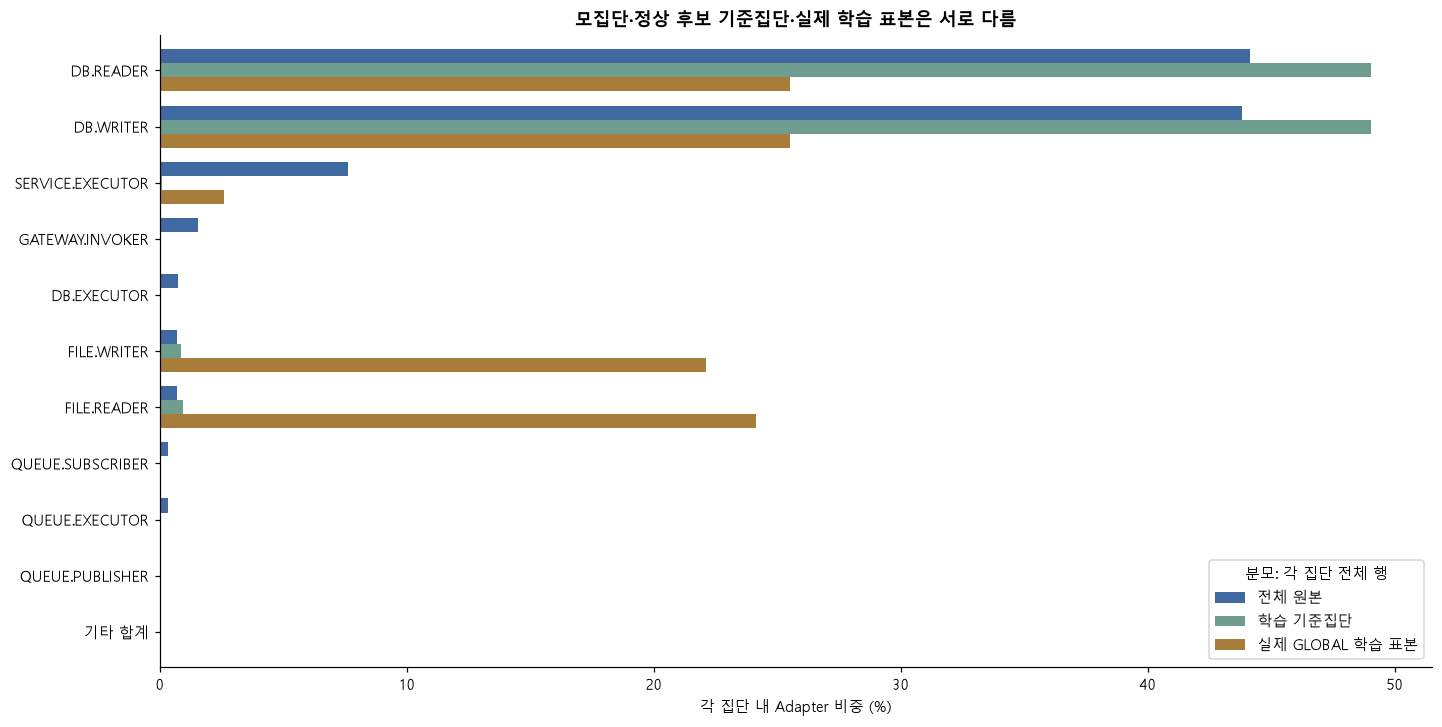

,전체 원본,학습 기준집단,실제 GLOBAL 학습 표본
DB.READER,1639795,1266772,"25,521"
DB.WRITER,1627833,1266649,"25,521"
SERVICE.EXECUTOR,282953,2621,"2,621"
GATEWAY.INVOKER,57285,3,3
DB.EXECUTOR,27271,2,2
FILE.WRITER,25498,22136,"22,136"
FILE.READER,25477,24151,"24,151"
QUEUE.SUBSCRIBER,13091,1,1
QUEUE.EXECUTOR,13087,2,2
QUEUE.PUBLISHER,1152,2,2


In [22]:
display(pd.DataFrame(pipeline.training_summary["splits"]))
display(adapter_model_support(pipeline))
fig, sample_mix = plot_training_mix(p, result, split, pipeline)
plt.show()
display(sample_mix)


## 부록 C. 실제 하이퍼파라미터와 점수 변환

아래는 저장 모델의 설정이다. 설정만 바꿔 읽는다고 기존 모델이 재학습되지는 않는다. 128개 트리·512개 트리 표본·최대 100,000개 fit 행·0.5/0.5 가중치·P99 정책은 초기 계산 비용/검토량 절충이며 최적화 실험 결과는 아니다.

`raw_score_threshold`는 개별 모델의 원시 점수 참고값이고 최종 앙상블 판정선은 `ensemble_threshold`다. 정규화 중앙값/간격은 모델마다 다르므로 원시 점수를 그대로 평균하지 않는다.


In [23]:
display(pd.DataFrame(pipeline.training_summary["config"].items(), columns=["설정", "저장 값"]))
display(pipeline.model_table()[["model", "train_sample_rows", "calibration_sample_rows",
    "calibration_center", "calibration_spread", "raw_score_threshold", "ensemble_threshold"]])
display(pd.DataFrame(pipeline.training_summary["versions"].items(), columns=["구성요소", "학습 버전"]))


,설정,저장 값
0,version,process-if-v1
1,n_estimators,128
2,max_samples,512
3,max_features,1
4,bootstrap,False
5,n_jobs,2
6,random_state,42
7,max_train_rows,100000
8,max_calibration_rows,100000
9,score_batch_rows,50000


,model,train_sample_rows,calibration_sample_rows,calibration_center,calibration_spread,raw_score_threshold,ensemble_threshold
0,GLOBAL,100000,100000,0.59532,0.08992,0.709954,1.274851
1,DB.READER,100000,72653,0.616901,0.030793,0.655141,0.697132
2,DB.WRITER,100000,72575,0.638452,0.01628,0.659177,0.704782
3,SERVICE.EXECUTOR,2621,35846,0.721872,0.02949,0.758392,1.0551


,구성요소,학습 버전
0,python,3.12.14
1,numpy,2.5.3
2,pandas,3.0.6
3,sklearn,1.9.1


## 부록 D. 기간·Adapter별 상세 분포

전체 분포에서 큰 DB 계열이 작은 Adapter를 가릴 수 있어 기간/집단을 분리한다. 다음 그림은 원본 기간의 구성이 얼마나 다른지, 그리고 입력의 시간대/요일이 어떻게 바뀌는지 보여준다. 일반 막대·선형 축·전수 비중을 사용한다.


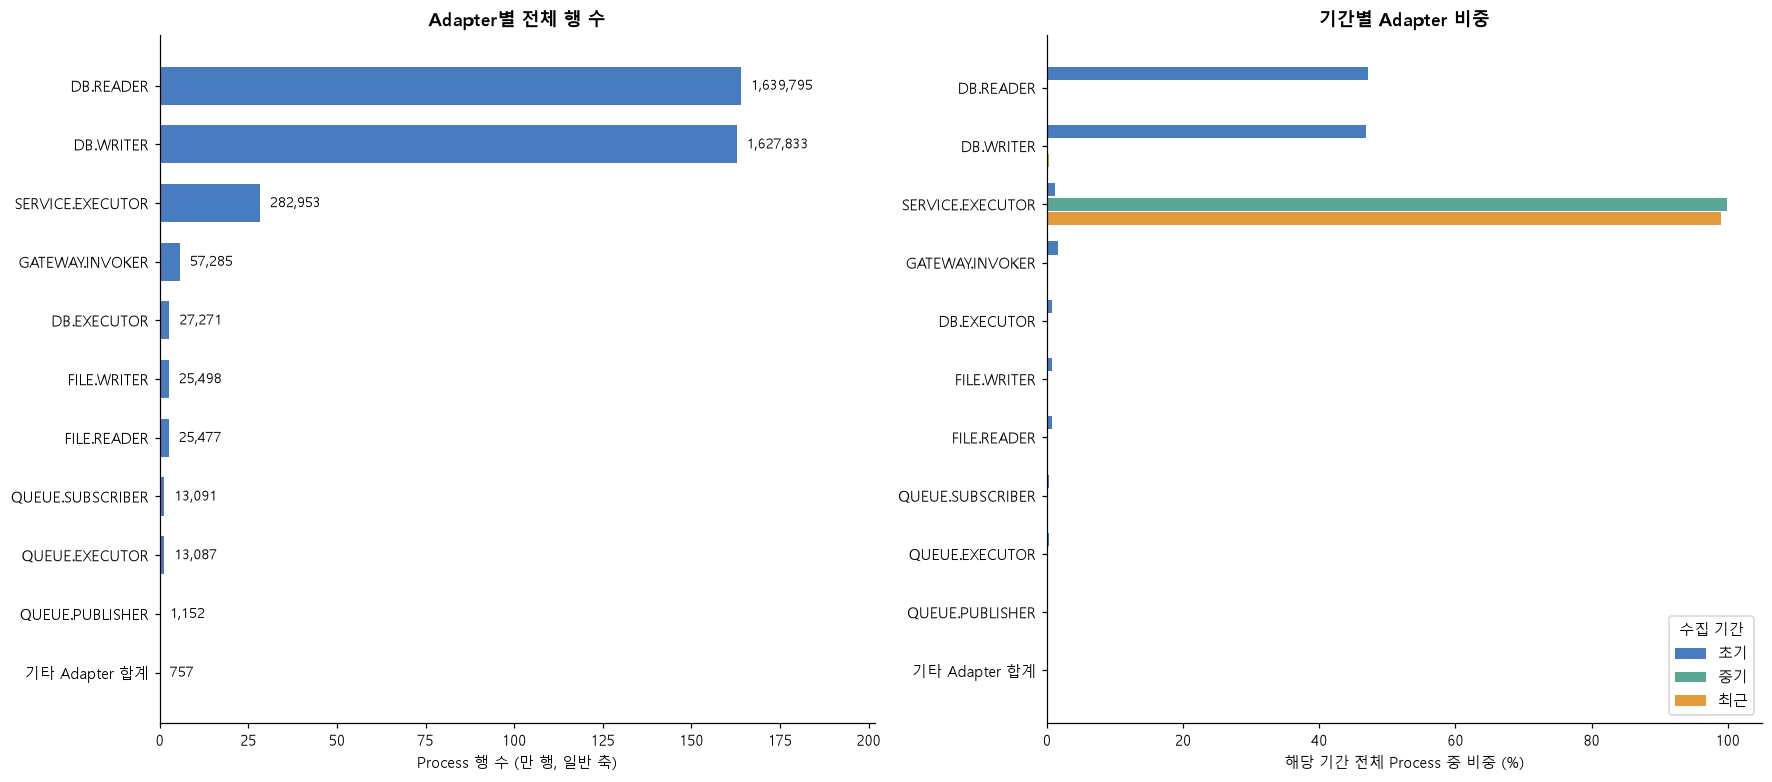

In [24]:
plot_population(p)
plt.show()


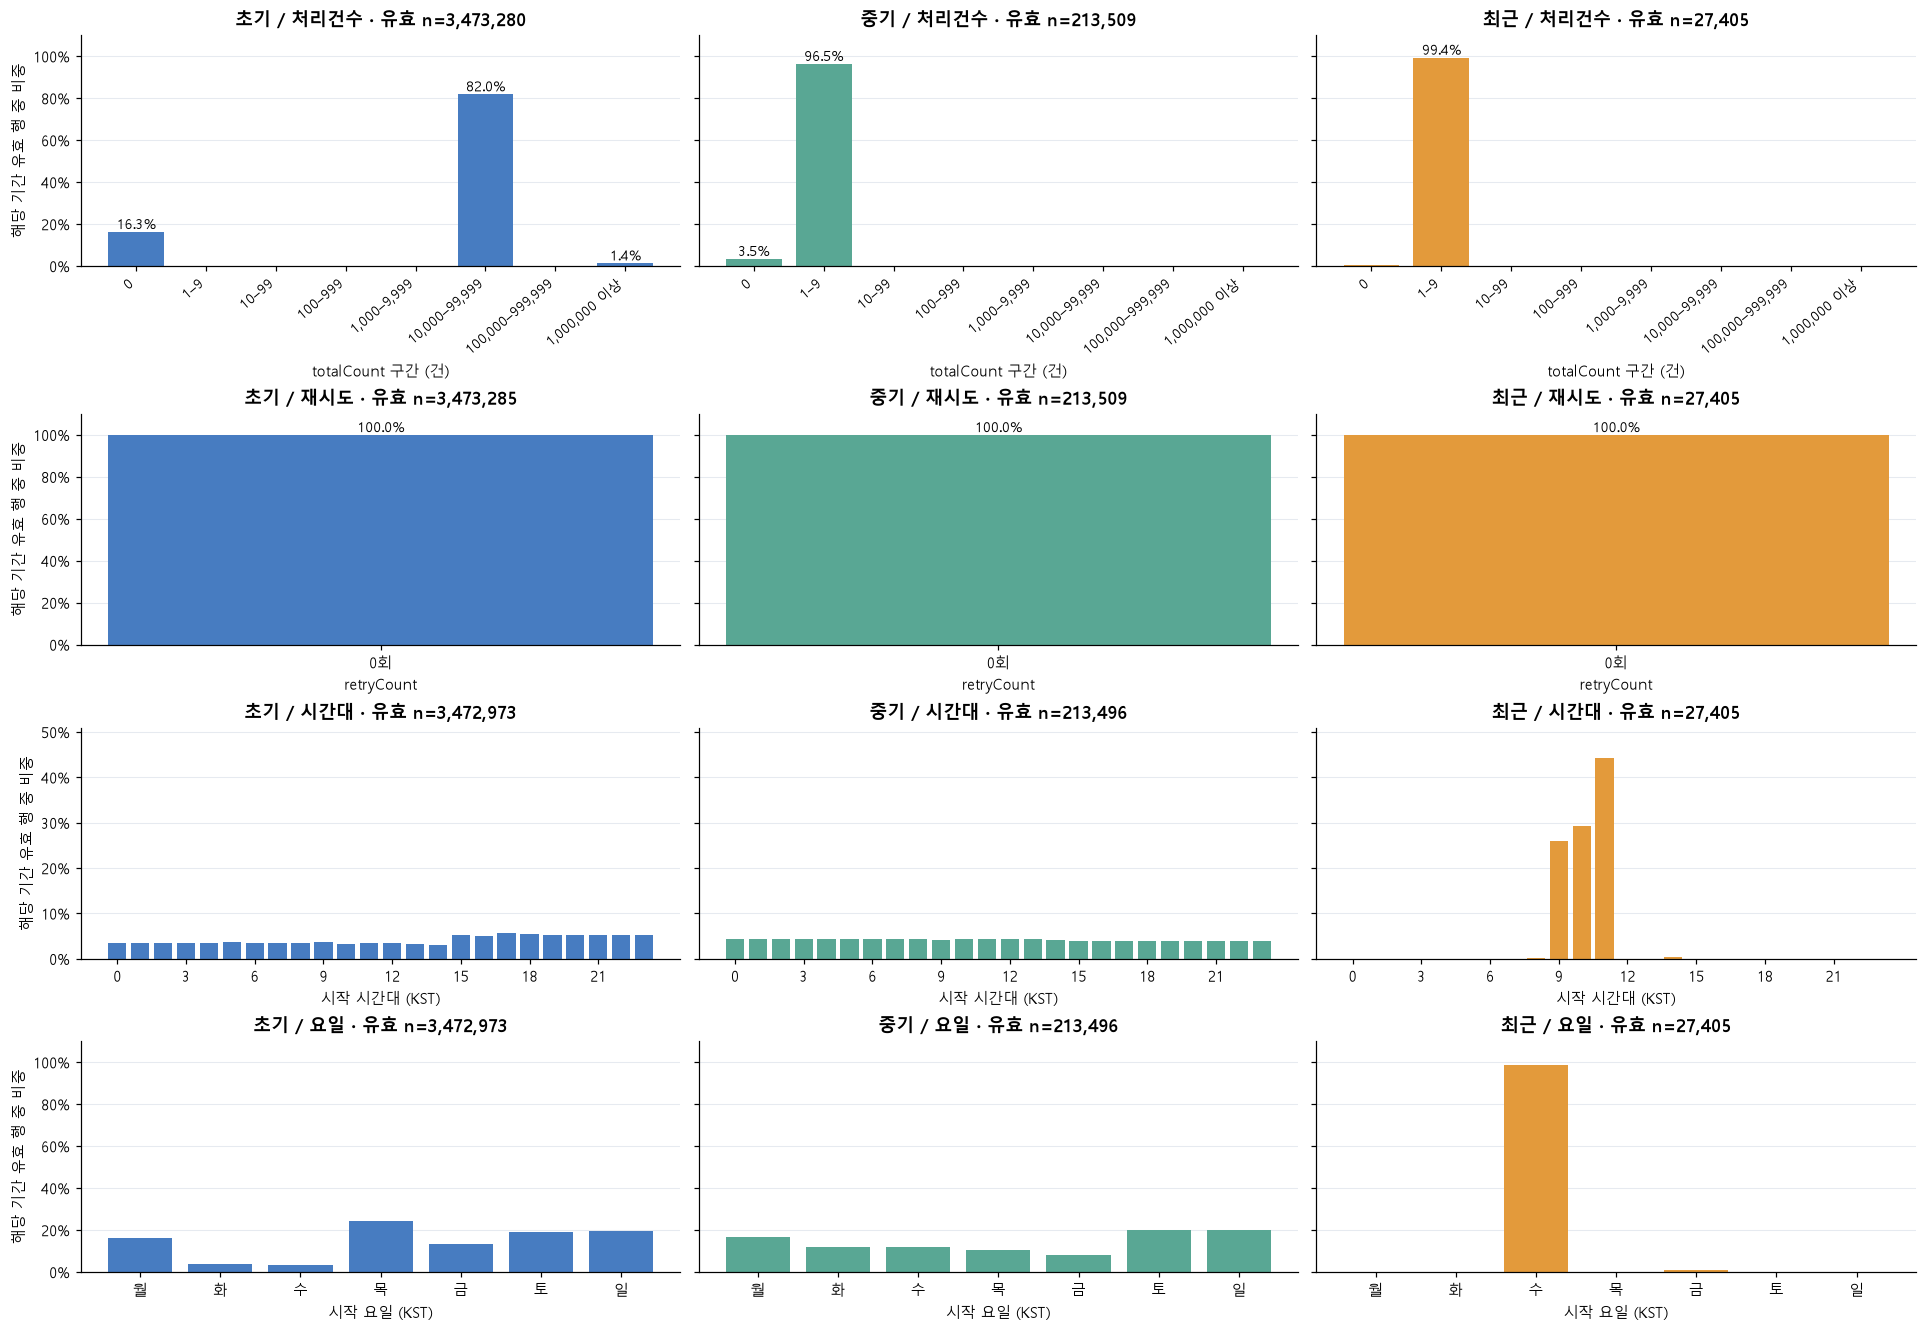

In [25]:
plot_input_features(p)
plt.show()


### 전문가별 처리시간 — 학습과 미래 test

과거 train과 미래 test의 처리시간 비중을 같은 단위 구간으로 비교한다. 표시된 P99/P99.9는 통계 규칙의 저장값이고, IF 점수 판정선과는 다른 종류의 기준이다. 긴 처리시간만으로 장애를 확정하지 않는다.


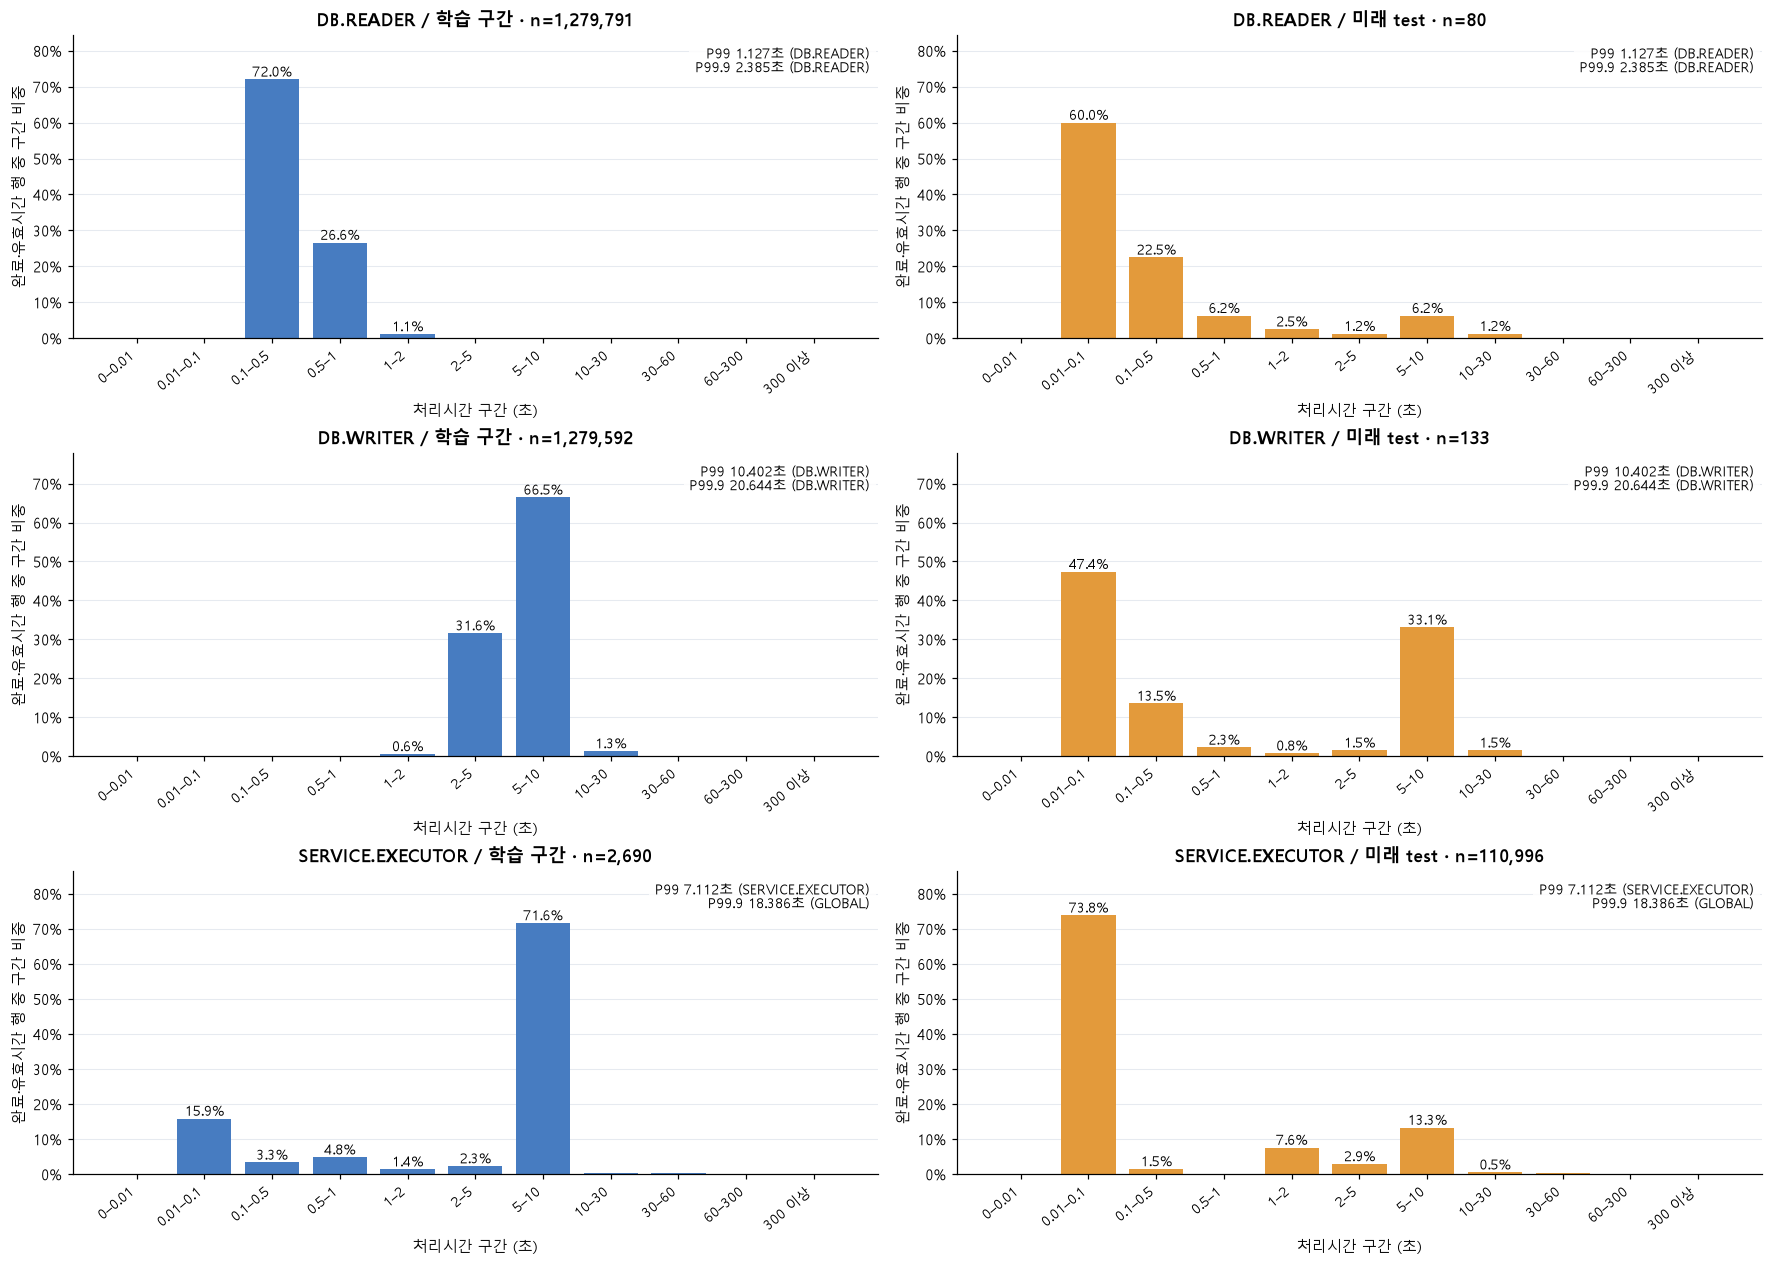

In [26]:
plot_duration_distributions(p, split, pipeline)
plt.show()


## 부록 E. 미래 test의 시간과 IF 초과폭

이 산점도는 분포 그림이 아니라 **언제 초과폭이 올라갔는가**를 보는 보조 그림이다. 0 위가 IF 후보이고 점의 표본 수는 그림에 표시한다. 샘플 그림으로 전체 후보 수를 세지 않는다. 특정 시간대 군집은 업무 스케줄/일괄 배치/분포 변화의 추가 확인 대상으로만 해석한다.


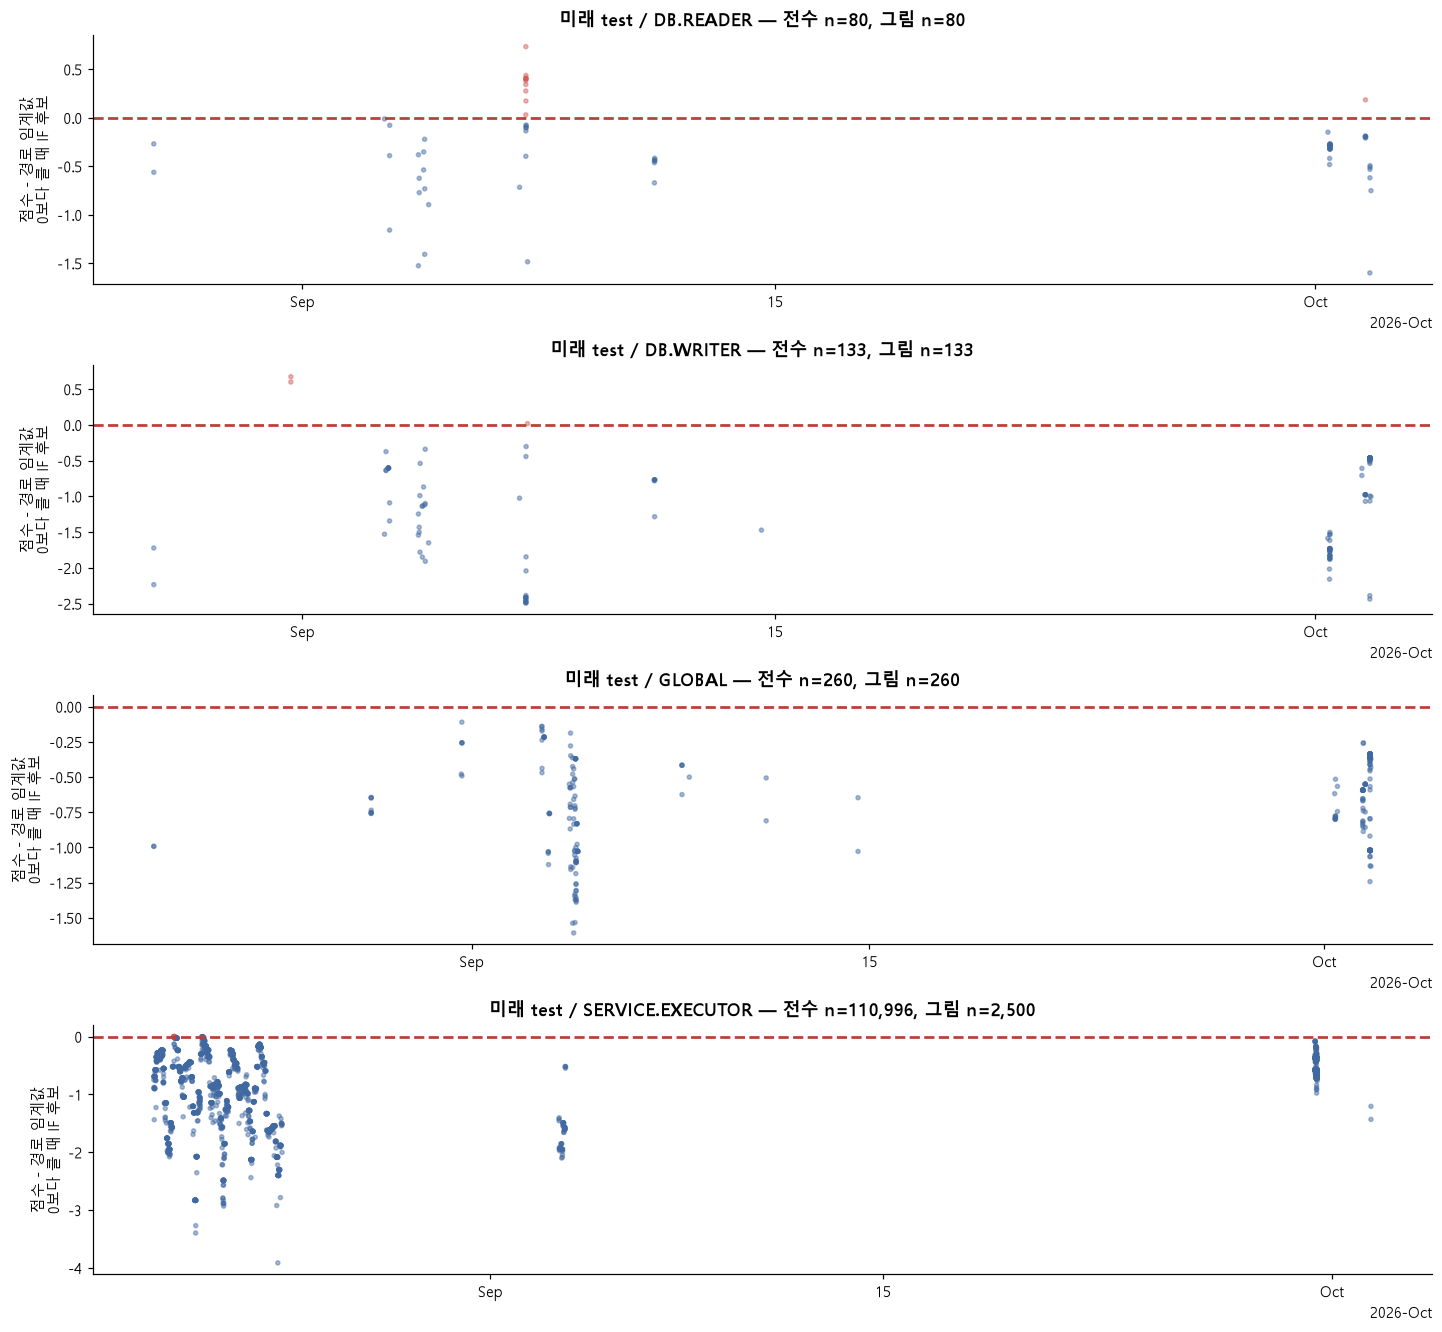

In [27]:
plot_test_score_timeline(p, result, split, pipeline)
plt.show()


### 운영 연결 시 주의

백엔드에는 Process 입력별 규칙 근거, IF 평가 여부, 모델 경로, 최종 점수·실제 threshold·초과폭을 함께 반환한다. `anomaly_candidate=False` 하나만 정상으로 해석하면 안 된다.

단건 Process에서 관계 규칙은 기본 미평가다. 부모 Transaction과 동일 허브/재시도의 모든 단계가 수집된 뒤에만 다시 평가한다. 후보 확정/오탐 검토는 메시지 원문과 담당자 확인을 통해 라벨을 추가하고, 그 라벨로 모델 가중치와 threshold 정책을 비교한다.
